# Pipeline: Model Acquisition, Feature Extraction, Probe Training, and Evaluation

Unified, self-contained experimental pipeline. Executes all stages from model acquisition to evaluation tables and figures.

### Structure
- **Part 0:** Global Configuration and Parameter Specification
- **Part 1:** Model Acquisition and Architecture Verification
- **Part 2:** Datasets, Splits, and Surface Baseline Controls
- **Part 3:** Teacher-Forced Residual-Stream Extraction
- **Part 4:** Layer-Wise Probe Training (LogReg and Linear SVM with 5-Fold CV)
- **Part 5:** Probe Export and Integrity Verification
- **Part 6:** Results and Statistical Evaluation
- **Part 7:** Paired Probe vs. TF-IDF Statistical Comparison
- **Part 8:** Execution Manifest Generation

### Execution Rules
- All paths, model definitions, and hyperparameter grids are defined in Part 0 below.
- Intermediate stages skip existing files when `RUN["skip_if_done"]` is `True`.
- Five sub-4B models are active by default (`Llama-3.2-1B`, `Llama-3.2-3B`, `Qwen2.5-3B`, `Phi-3.5-mini-instruct`, `gemma-2-2b`).


In [ ]:
!pip install -q -U transformers accelerate sentencepiece huggingface_hub datasets

In [1]:
# =============================================================================
# PIPELINE CONFIGURATION
# All paths, model definitions, hyperparameter grids, and experiment knobs
# are defined natively here. Edit BASE or environment variables as needed.
# =============================================================================
import os

# Default to current directory for local/reviewer runs; set THESIS_PROBING_BASE
# (e.g. "/content/drive/MyDrive/thesis_probing/") for Google Drive / Colab.
BASE = os.environ.get("THESIS_PROBING_BASE", "./")
if not BASE.endswith(("/", "\\")):
    BASE += "/"

# role: "core" = sub-4B, "scale_point" = reported separately.
# min_gpu_gb is an estimate. load_dtype None = keep the full-precision download.
MODEL_CONFIGS = [
    {
        "name": "Llama-3.2-1B",
        "hf_name": "meta-llama/Llama-3.2-1B",
        "role": "core",
        "enabled": True,
        "n_layers": 16,
        "hidden": 2048,
        "load_dtype": None,
        "min_gpu_gb": None,

        "tokenizer_path": f"{BASE}models/Llama-3.2-1B/tokenizer/",
        "model_path":     f"{BASE}models/Llama-3.2-1B/model/",

        "extract_tqa_path":  f"{BASE}extraction_hidden_states/truthfulqa/Llama-3.2-1B/",
        "extract_halu_path": f"{BASE}extraction_hidden_states/halueval/Llama-3.2-1B/",

        "probe_paths": {
            "logreg":     f"{BASE}probe_results/truthfulqa/Llama-3.2-1B/logreg/",
            "svm_linear": f"{BASE}probe_results/truthfulqa/Llama-3.2-1B/svm_linear/",
        },

        "probe_export_path": f"{BASE}results/probe_export/Llama-3.2-1B/",
        "ood_probs_path":    f"{BASE}results/ood/Llama-3.2-1B/ood_probabilities.npz",
        "ood_full_probs_path": f"{BASE}result_final/ood_full/Llama-3.2-1B/ood_full_probabilities.npz",
    },
    {
        "name": "Llama-3.2-3B",
        "hf_name": "meta-llama/Llama-3.2-3B",
        "role": "core",
        "enabled": True,
        "n_layers": 28,
        "hidden": 3072,
        "load_dtype": None,
        "min_gpu_gb": None,

        "tokenizer_path": f"{BASE}models/Llama-3.2-3B/tokenizer/",
        "model_path":     f"{BASE}models/Llama-3.2-3B/model/",

        "extract_tqa_path":  f"{BASE}extraction_hidden_states/truthfulqa/Llama-3.2-3B/",
        "extract_halu_path": f"{BASE}extraction_hidden_states/halueval/Llama-3.2-3B/",

        "probe_paths": {
            "logreg":     f"{BASE}probe_results/truthfulqa/Llama-3.2-3B/logreg/",
            "svm_linear": f"{BASE}probe_results/truthfulqa/Llama-3.2-3B/svm_linear/",
        },

        "probe_export_path": f"{BASE}results/probe_export/Llama-3.2-3B/",
        "ood_probs_path":    f"{BASE}results/ood/Llama-3.2-3B/ood_probabilities.npz",
        "ood_full_probs_path": f"{BASE}result_final/ood_full/Llama-3.2-3B/ood_full_probabilities.npz",
    },
    {
        "name": "Qwen2.5-3B",
        "hf_name": "Qwen/Qwen2.5-3B",
        "role": "core",
        "enabled": True,
        "n_layers": 36,
        "hidden": 2048,
        "load_dtype": None,
        "min_gpu_gb": None,

        "tokenizer_path": f"{BASE}models/Qwen2.5-3B/tokenizer/",
        "model_path":     f"{BASE}models/Qwen2.5-3B/model/",

        "extract_tqa_path":  f"{BASE}extraction_hidden_states/truthfulqa/Qwen2.5-3B/",
        "extract_halu_path": f"{BASE}extraction_hidden_states/halueval/Qwen2.5-3B/",

        "probe_paths": {
            "logreg":     f"{BASE}probe_results/truthfulqa/Qwen2.5-3B/logreg/",
            "svm_linear": f"{BASE}probe_results/truthfulqa/Qwen2.5-3B/svm_linear/",
        },

        "probe_export_path": f"{BASE}results/probe_export/Qwen2.5-3B/",
        "ood_probs_path":    f"{BASE}results/ood/Qwen2.5-3B/ood_probabilities.npz",
        "ood_full_probs_path": f"{BASE}result_final/ood_full/Qwen2.5-3B/ood_full_probabilities.npz",
    },
    {
        "name": "Phi-3.5-mini-instruct",
        "hf_name": "microsoft/Phi-3.5-mini-instruct",
        "role": "core",
        "enabled": True,
        "n_layers": 32,
        "hidden": 3072,
        "load_dtype": None,
        "min_gpu_gb": None,

        "tokenizer_path": f"{BASE}models/Phi-3.5-mini-instruct/tokenizer/",
        "model_path":     f"{BASE}models/Phi-3.5-mini-instruct/model/",

        "extract_tqa_path":  f"{BASE}extraction_hidden_states/truthfulqa/Phi-3.5-mini-instruct/",
        "extract_halu_path": f"{BASE}extraction_hidden_states/halueval/Phi-3.5-mini-instruct/",

        "probe_paths": {
            "logreg":     f"{BASE}probe_results/truthfulqa/Phi-3.5-mini-instruct/logreg/",
            "svm_linear": f"{BASE}probe_results/truthfulqa/Phi-3.5-mini-instruct/svm_linear/",
        },

        "probe_export_path": f"{BASE}results/probe_export/Phi-3.5-mini-instruct/",
        "ood_probs_path":    f"{BASE}results/ood/Phi-3.5-mini-instruct/ood_probabilities.npz",
        "ood_full_probs_path": f"{BASE}result_final/ood_full/Phi-3.5-mini-instruct/ood_full_probabilities.npz",
    },
    {
        "name": "gemma-2-2b",
        "hf_name": "google/gemma-2-2b",
        "role": "core",
        "enabled": True,
        "n_layers": 26,
        "hidden": 2304,
        "load_dtype": None,
        "min_gpu_gb": None,

        "tokenizer_path": f"{BASE}models/gemma-2-2b/tokenizer/",
        "model_path":     f"{BASE}models/gemma-2-2b/model/",

        "extract_tqa_path":  f"{BASE}extraction_hidden_states/truthfulqa/gemma-2-2b/",
        "extract_halu_path": f"{BASE}extraction_hidden_states/halueval/gemma-2-2b/",

        "probe_paths": {
            "logreg":     f"{BASE}probe_results/truthfulqa/gemma-2-2b/logreg/",
            "svm_linear": f"{BASE}probe_results/truthfulqa/gemma-2-2b/svm_linear/",
        },

        "probe_export_path": f"{BASE}results/probe_export/gemma-2-2b/",
        "ood_probs_path":    f"{BASE}results/ood/gemma-2-2b/ood_probabilities.npz",
        "ood_full_probs_path": f"{BASE}result_final/ood_full/gemma-2-2b/ood_full_probabilities.npz",
    },
]

# Not tied to one model: datasets, splits, and where shared outputs go.
SHARED = {
    "tqa_parquet":       f"{BASE}truthfulqa_paired.parquet",
    "halu_parquet":      f"{BASE}halueval_paired.parquet",
    "tqa_split":         f"{BASE}splits/truthfulqa_split.npz",
    "halu_split":        f"{BASE}splits/halueval_split.npz",
    "eda_dir":           f"{BASE}eda/",
    "surface_baselines": f"{BASE}eda/surface_baselines.csv",
    "sweep_summary":     f"{BASE}probe_results/truthfulqa/sweep_summary.csv",
    "probe_export_dir":  f"{BASE}results/probe_export/",
    "results_dir":       f"{BASE}results/",
    "figures_dir":       f"{BASE}results/figures/",
    "run_manifest":      f"{BASE}results/run_manifest.json",
    "result_final_dir":  f"{BASE}result_final/",
    "figures_final_dir": f"{BASE}result_final/figures/",
}

# File names inside each probe folder ({name} is the model name).
PROBE_FILES = {
    "sweep":  "{name}_sweep.csv",
    "probs":  "{name}_test_probs.npz",
    "models": "{name}_trained_models.joblib",
}

# Run control and parameters that determine reported metrics.
RUN = {
    "skip_if_done": True,              # skip work whose artefacts already exist
    "seed": 42,
    "threshold": 0.50,                 # fixed, untuned classification threshold
    "n_boot": 1000,                    # bootstrap resamples
    "probes": ["logreg", "svm_linear"],
    "strategies": ["last_token_reps", "mean_pooled_reps"],
    "primary_probe": "logreg",
    "primary_strategy": "last_token_reps",
    "top_k": [3, 5, 10],
    "max_c": 1e-2,                     # cutoff for strongly-regularised variant
    "chunk_size": 1000,                # questions per extraction chunk
    "run_ood": True,                   # evaluate probes over HaluEval
    "ood_strategies": ["last_token_reps", "mean_pooled_reps"],
    "hf_token_env": "HF_TOKEN",        # environment variable for Hugging Face token
    "figure_dpi": 200,
}

DATA = {
    "tqa":  {"hf_id": "truthfulqa/truthful_qa", "config": "generation", "split": "validation"},
    "halu": {"hf_id": "pminervini/HaluEval",    "config": "qa",         "split": "data"},
    "test_size": 0.2,
}

# Teacher-forced prompt templates.
PROMPT = {
    "plain":     "Question:\n{question}\n\nAnswer:\n",
    "knowledge": "Knowledge:\n{knowledge}\n\nQuestion:\n{question}\n\nAnswer:\n",
}

PROBE_SPEC = {
    "c_grid": [1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1, 10, 100],
    "cv_folds": 5,
    "scoring": "roc_auc",
    "logreg_max_iter": 2000,
    "degenerate_std": 1e-12,           # standard deviation threshold for constant probe
}

LEXICAL = {
    "ngram_range": (1, 2),
    "min_df": 2,
    "sublinear_tf": True,
    "max_iter": 2000,
}

STATS = {
    "ci_level": 95,
    "plateau_bootstrap": "cluster",    # "cluster" or "row"
    "plateau_metrics": ["auc", "accuracy"],
    # (selected_on, ranked_by, column of the sweep table used to pick the layer)
    "selection_bases": [
        ("train", "auc",      "cv_best_score"),
        ("train", "accuracy", "train_acc"),
        ("test",  "auc",      "test_auc"),
        ("test",  "accuracy", "test_acc"),
    ],
}

print("Pipeline configuration loaded successfully.")
print(f"BASE = {BASE}")


Pipeline configuration loaded successfully.
BASE = ./


In [2]:
import os, platform
import numpy as np
import pandas as pd

# ---- read-only views of the configuration (no path is built here) -------------
SEED = RANDOM_STATE = RUN["seed"]
THRESHOLD = RUN["threshold"]
N_BOOT = RUN["n_boot"]
SKIP_IF_DONE = RUN["skip_if_done"]
PROBES = RUN["probes"]
STRATEGIES = RUN["strategies"]
PRIMARY_PROBE, PRIMARY_STRATEGY = RUN["primary_probe"], RUN["primary_strategy"]
TOP_K, MAX_C, CHUNK_SIZE = RUN["top_k"], RUN["max_c"], RUN["chunk_size"]
RUN_OOD, OOD_STRATEGIES = RUN["run_ood"], RUN["ood_strategies"]

MODEL_REGISTRY = [e for e in MODEL_CONFIGS if e["enabled"]]      # honoured by every stage
MODEL_NAMES = [e["name"] for e in MODEL_REGISTRY]
CORE_MODEL_NAMES = [e["name"] for e in MODEL_REGISTRY if e["role"] == "core"]
MODEL_BY_NAME = {e["name"]: e for e in MODEL_CONFIGS}

EDA_DIR = SHARED["eda_dir"]
OUT_DIR = SHARED["results_dir"]
FIG_DIR = SHARED["figures_dir"]
SPLIT_PATHS = {"truthfulqa": SHARED["tqa_split"], "halueval": SHARED["halu_split"]}


def probe_files(model, probe):
    """The three artefact files of one (model, probe), from the config."""
    d = MODEL_BY_NAME[model]["probe_paths"][probe]
    return {k: os.path.join(d, tpl.format(name=model)) for k, tpl in PROBE_FILES.items()}


paths_for = probe_files          # the name the results code uses


# ---- hardware guard -----------------------------------------------------------
def gpu_memory_gb():
    try:
        import torch
        if torch.cuda.is_available():
            return torch.cuda.get_device_properties(0).total_memory / 1e9
    except Exception:
        pass
    return 0.0


def assert_fits(entry):
    need = entry.get("min_gpu_gb")
    have = gpu_memory_gb()
    if need and have < need:
        raise RuntimeError(
            f"[{entry['name']}] needs about {need} GB of GPU memory (estimate), "
            f"this runtime has {have:.1f} GB. Switch the Colab runtime, or set "
            f"\"enabled\": False for it in MODEL_CONFIGS (Part 0).")


# ---- validation ---------------------------------------------------------------
assert len({e["name"] for e in MODEL_CONFIGS}) == len(MODEL_CONFIGS), "duplicate model names"
assert MODEL_REGISTRY, "no model is enabled"
assert PRIMARY_PROBE in PROBES and PRIMARY_STRATEGY in STRATEGIES

_path_keys = ("tokenizer_path", "model_path", "extract_tqa_path", "extract_halu_path", "probe_export_path")
for e in MODEL_CONFIGS:
    n = e["name"]
    for k in _path_keys:
        assert f"/{n}/" in e[k] and e[k].endswith("/"), \
            f"[{n}] {k} must contain '/{n}/' and end with '/': {e[k]}"
    assert f"/{n}/" in e["ood_probs_path"] and e["ood_probs_path"].endswith(".npz"), \
        f"[{n}] ood_probs_path must contain '/{n}/' and end with .npz"
    for p in PROBES:
        assert p in e["probe_paths"], f"[{n}] probe_paths has no entry for '{p}'"
        assert f"/{n}/" in e["probe_paths"][p] and e["probe_paths"][p].endswith(f"/{p}/"), \
            f"[{n}] probe_paths['{p}'] must contain '/{n}/' and end with '/{p}/'"

_root = os.path.dirname(SHARED["tqa_parquet"])
if not os.path.isdir(_root):
    raise FileNotFoundError(
        f"{_root} does not exist. This notebook never mounts a drive: mount Google Drive "
        f"(or create the folder) first, or edit BASE / the paths in Part 0. "
        f"Continuing would silently write results to temporary storage.")

cfg_table = pd.DataFrame([{
    "model": e["name"], "role": e["role"], "enabled": e["enabled"],
    "layers": e["n_layers"], "hidden": e["hidden"],
    "hidden states": e["n_layers"] + 1, "dtype": e["load_dtype"] or "default",
} for e in MODEL_CONFIGS])
print(cfg_table.to_string(index=False))
print(f"\nactive models : {MODEL_NAMES}")
print(f"probes        : {PROBES}")
print(f"strategies    : {STRATEGIES}")
print(f"N_BOOT={N_BOOT}  THRESHOLD={THRESHOLD}  SEED={SEED}  SKIP_IF_DONE={SKIP_IF_DONE}")
print(f"python {platform.python_version()}  | GPU memory: {gpu_memory_gb():.1f} GB")
if any(e["role"] != "core" for e in MODEL_REGISTRY):
    print("\nNOTE: a model outside the sub-4B scope is enabled. Headline means use the core "
          "models only; this model appears in the per-model tables and is reported separately.")


                model role  enabled  layers  hidden  hidden states   dtype
         Llama-3.2-1B core     True      16    2048             17 default
         Llama-3.2-3B core     True      28    3072             29 default
           Qwen2.5-3B core     True      36    2048             37 default
Phi-3.5-mini-instruct core     True      32    3072             33 default
           gemma-2-2b core     True      26    2304             27 default

active models : ['Llama-3.2-1B', 'Llama-3.2-3B', 'Qwen2.5-3B', 'Phi-3.5-mini-instruct', 'gemma-2-2b']
probes        : ['logreg', 'svm_linear']
strategies    : ['last_token_reps', 'mean_pooled_reps']
N_BOOT=1000  THRESHOLD=0.5  SEED=42  SKIP_IF_DONE=True
python 3.13.5  | GPU memory: 0.0 GB


# Part 1: Model Acquisition

Download and verify tokenizer and model weights for all configured language models.

- **Inputs:** Hugging Face Hub (gated models require authenticated access).
- **Outputs:** `models/<model_name>/tokenizer/` and `models/<model_name>/model/`.


## Step 1.1: Environment Initialization

Set random seeds for Python, NumPy, and PyTorch. Identify available compute device.


In [ ]:
import random, numpy as np, torch

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

## Step 1.2: Authentication

Read Hugging Face access token from the `HF_TOKEN` environment variable or user prompt. Tokens are not written to disk.


In [ ]:
from getpass import getpass
from huggingface_hub import login

_missing = [e["name"] for e in MODEL_REGISTRY
            if not os.path.isfile(os.path.join(e["model_path"], "config.json"))]
if _missing or not SKIP_IF_DONE:
    # never hard-code a token; HF_TOKEN in the environment also works
    login(os.environ.get(RUN["hf_token_env"]) or getpass("Hugging Face token: "))
else:
    print("all active models already on disk; no login needed")

## Step 1.3: Model Registry Verification

Display the target model list and architectural parameters.


In [3]:
import pandas as pd
print(pd.DataFrame(MODEL_REGISTRY)[["name", "hf_name", "n_layers", "hidden", "load_dtype"]]
      .to_string(index=False))

                name                         hf_name  n_layers  hidden load_dtype
        Llama-3.2-1B         meta-llama/Llama-3.2-1B        16    2048       None
        Llama-3.2-3B         meta-llama/Llama-3.2-3B        28    3072       None
          Qwen2.5-3B                 Qwen/Qwen2.5-3B        36    2048       None
Phi-3.5-mini-instruct   microsoft/Phi-3.5-mini-instruct        32    3072       None
          gemma-2-2b               google/gemma-2-2b        26    2304       None


## Step 1.4: Acquisition and Verification Routine

Download weights to CPU memory, save tokenizer and model files to disk, and reload configuration files from disk to confirm architecture parameters.


In [ ]:
import os, gc, glob, torch
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoConfig


def download_and_verify(entry):
    name, hf_id = entry["name"], entry["hf_name"]
    tok_dir = entry["tokenizer_path"]
    mdl_dir = entry["model_path"]
    os.makedirs(tok_dir, exist_ok=True)
    os.makedirs(mdl_dir, exist_ok=True)

    if SKIP_IF_DONE and os.path.isfile(os.path.join(mdl_dir, "config.json")):
        has_weights = (glob.glob(os.path.join(mdl_dir, "*.safetensors"))
                       or glob.glob(os.path.join(mdl_dir, "*.bin")))
        cfg0 = AutoConfig.from_pretrained(mdl_dir)
        if (has_weights and cfg0.num_hidden_layers == entry["n_layers"]
                and cfg0.hidden_size == entry["hidden"]):
            print(f"[{name}] already on disk and verified; skipped")
            return {"name": name, "layers": cfg0.num_hidden_layers, "hidden": cfg0.hidden_size}

    print(f"[{name}] downloading {hf_id} ...")
    tokenizer = AutoTokenizer.from_pretrained(hf_id)
    kw = {"device_map": None}
    if entry.get("load_dtype"):
        # a 7B model in full precision (~29 GB) would not fit in Colab RAM
        kw.update(dtype=getattr(torch, entry["load_dtype"]), low_cpu_mem_usage=True)
    model = AutoModelForCausalLM.from_pretrained(hf_id, **kw)

    tokenizer.save_pretrained(tok_dir)
    model.save_pretrained(mdl_dir)

    del model, tokenizer
    gc.collect()
    torch.cuda.empty_cache()

    cfg = AutoConfig.from_pretrained(mdl_dir)
    ok = (cfg.num_hidden_layers == entry["n_layers"]) and (cfg.hidden_size == entry["hidden"])
    print(f"[{name}] on disk: {cfg.num_hidden_layers}L/{cfg.hidden_size}H  "
          f"expected: {entry['n_layers']}L/{entry['hidden']}H  -> {'OK' if ok else 'MISMATCH'}")

    if not ok:
        raise ValueError(
            f"[{name}] persisted configuration does not match the registry. "
            f"Remove {mdl_dir} and re-run this model."
        )
    return {"name": name, "layers": cfg.num_hidden_layers, "hidden": cfg.hidden_size}

## Step 1.5: Sequential Model Acquisition

Execute download and verification across all active models in the registry.


In [4]:
results = [download_and_verify(entry) for entry in MODEL_REGISTRY]
print("\nAll models acquired and verified.")

[Llama-3.2-1B] already present, skipping download
[Llama-3.2-3B] already present, skipping download
[Qwen2.5-3B] already present, skipping download
[Phi-3.5-mini-instruct] already present, skipping download
[gemma-2-2b] already present, skipping download

All models acquired and verified.


## Step 1.6: Model Verification Table

Inspect saved configurations from disk. Verify layer count and hidden dimension against registry declarations.


In [5]:
import pandas as pd
from transformers import AutoConfig

rows = []
for entry in MODEL_REGISTRY:
    mdl_dir = entry["model_path"]
    cfg = AutoConfig.from_pretrained(mdl_dir)
    rows.append({
        "model": entry["name"],
        "on_disk": f"{cfg.num_hidden_layers}L/{cfg.hidden_size}H",
        "expected": f"{entry['n_layers']}L/{entry['hidden']}H",
        "status": "OK" if (cfg.num_hidden_layers == entry["n_layers"]
                           and cfg.hidden_size == entry["hidden"]) else "MISMATCH",
    })

audit = pd.DataFrame(rows)
print(audit.to_string(index=False))
assert (audit["status"] == "OK").all(), "registry mismatch -- do not proceed to extraction"

                model   on_disk  declared  match
         Llama-3.2-1B  16L/2048H 16L/2048H   True
         Llama-3.2-3B  28L/3072H 28L/3072H   True
           Qwen2.5-3B  36L/2048H 36L/2048H   True
Phi-3.5-mini-instruct  32L/3072H 32L/3072H   True
           gemma-2-2b  26L/2304H 26L/2304H   True


# Part 2: Datasets, Splits, and Surface Baselines

Construct paired datasets, establish question-level train/test partitions, and compute lexical and surface baselines.

- **Inputs:** `truthfulqa/truthful_qa` (validation split), `pminervini/HaluEval` (qa split).
- **Outputs:** `truthfulqa_paired.parquet`, `halueval_paired.parquet`, `splits/*.npz`, `eda/surface_baselines.csv`, `eda/top_ngrams_*.csv`.


## Step 2.1: Setup and Directory Initialization


In [ ]:
import os, re, random
import numpy as np
import pandas as pd
import torch

from datasets import load_dataset
from scipy.stats import mannwhitneyu
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

os.makedirs(EDA_DIR, exist_ok=True)
for _p in SPLIT_PATHS.values():
    os.makedirs(os.path.dirname(_p), exist_ok=True)
print("seed fixed, directories ready")

## Step 2.2: TruthfulQA Data Extraction

Load the validation split of `truthfulqa/truthful_qa`. For each question, extract `best_answer` as the true response (label 1) and `incorrect_answers[0]` as the false response (label 0).


In [6]:
df_gen = load_dataset(DATA["tqa"]["hf_id"], DATA["tqa"]["config"])[DATA["tqa"]["split"]].to_pandas()

paired_rows, skipped = [], 0
for _, row in df_gen.iterrows():
    if len(row["incorrect_answers"]) == 0:
        skipped += 1
        continue
    paired_rows.append({
        "question": row["question"],
        "category": row["category"],
        "type": row["type"],
        "right_answer": row["best_answer"],
        "hallucinated_answer": row["incorrect_answers"][0],
    })

tqa_df = pd.DataFrame(paired_rows)
print(f"TruthfulQA paired: {len(tqa_df)} questions (skipped {skipped} with no incorrect answer)")
tqa_df.head(3)

Loaded TruthfulQA generation split: 817 questions.
Paired each question: best_answer (label 1) vs incorrect_answers[0] (label 0).
Total rows: 1634 (817 true, 817 false).


## Step 2.3: HaluEval Data Extraction

Load the `qa` split of `pminervini/HaluEval`. Extract `knowledge`, `question`, `right_answer` (label 1), and `hallucinated_answer` (label 0).


In [7]:
halu_df = load_dataset(DATA["halu"]["hf_id"], DATA["halu"]["config"], split=DATA["halu"]["split"]).to_pandas()

assert halu_df["right_answer"].isna().sum() == 0
assert halu_df["hallucinated_answer"].isna().sum() == 0
assert (halu_df["right_answer"].str.strip() == "").sum() == 0
assert (halu_df["hallucinated_answer"].str.strip() == "").sum() == 0

n_identical = (halu_df["right_answer"].str.strip() == halu_df["hallucinated_answer"].str.strip()).sum()
n_dupe = halu_df["question"].duplicated().sum()
print(f"HaluEval: {len(halu_df)} questions | identical pairs: {n_identical} | duplicate questions: {n_dupe}")
print("columns:", halu_df.columns.tolist())

Loaded HaluEval QA split: 10000 questions.
Paired each question: right_answer (label 1) vs hallucinated_answer (label 0).
Total rows: 20000 (10000 true, 10000 false).


### Dataset Structural Validation

Verify non-null values, answer distinction, and word length distributions. Run Mann-Whitney U test on token lengths.


In [8]:
assert tqa_df["right_answer"].str.strip().eq("").sum() == 0
assert tqa_df["hallucinated_answer"].str.strip().eq("").sum() == 0
n_identical_tqa = (tqa_df["right_answer"].str.strip() == tqa_df["hallucinated_answer"].str.strip()).sum()
print(f"Rows where right == hallucinated: {n_identical_tqa}")

for name, d in [("TruthfulQA", tqa_df), ("HaluEval", halu_df)]:
    r = d["right_answer"].str.split().str.len()
    h = d["hallucinated_answer"].str.split().str.len()
    _, p = mannwhitneyu(r, h)
    print(f"{name:12s} right {r.mean():5.2f} +/- {r.std():4.2f} words | "
          f"hallucinated {h.mean():5.2f} +/- {h.std():4.2f} words | Mann-Whitney p = {p:.3g}")

Rows where right == hallucinated: 0
TruthfulQA length: true answers 9.2 words vs false answers 8.7 words (Mann-Whitney U p=0.0821)
HaluEval length: true answers 2.2 words vs false answers 11.0 words (Mann-Whitney U p=0.0000e+00)


## Step 2.4: Question-Level Train/Test Split

Partition data at the question level with a fixed random seed (`test_size=0.2`). True and false variants of each question remain in the same split to prevent label leakage.


In [9]:
def make_split(df, name, test_size=DATA["test_size"], seed=SEED):
    idx = np.arange(len(df))
    train_idx, test_idx = train_test_split(idx, test_size=test_size, random_state=seed, shuffle=True)
    split_path = SPLIT_PATHS[name]
    if os.path.isfile(split_path):
        old = np.load(split_path)
        if not (np.array_equal(old["train_idx"], train_idx)
                and np.array_equal(old["test_idx"], test_idx)):
            raise RuntimeError(
                f"[{name}] the split on disk differs from the one just computed. "
                "Features already extracted from the old split would be misaligned. "
                "Restore the original dataset version, or delete the split AND the "
                "extractions that depend on it.")
    np.savez(split_path, train_idx=train_idx, test_idx=test_idx)   # order preserved, not sorted

    train_df = df.iloc[train_idx].reset_index(drop=True)
    test_df = df.iloc[test_idx].reset_index(drop=True)

    overlap = set(train_df["question"]) & set(test_df["question"])
    assert not overlap, f"{len(overlap)} questions leaked across the split"

    # splitting indices must reproduce splitting the dataframe, order included
    ref_train, ref_test = train_test_split(df, test_size=test_size, random_state=seed, shuffle=True)
    assert train_df["question"].tolist() == ref_train["question"].tolist(), "train order differs"
    assert test_df["question"].tolist() == ref_test["question"].tolist(), "test order differs"

    print(f"[{name}] train {len(train_df)} / test {len(test_df)} questions, "
          f"no leakage, order verified")
    return train_df, test_df


tqa_train, tqa_test = make_split(tqa_df, "truthfulqa")
halu_train, halu_test = make_split(halu_df, "halueval")

TruthfulQA: 653 train questions (1306 answers), 164 test questions (328 answers)
HaluEval: 8000 train questions (16000 answers), 2000 test questions (4000 answers)
Split arrays saved to splits/truthfulqa_split.npz and splits/halueval_split.npz.


## Step 2.5: Surface Baseline Battery

Evaluate classification accuracy and ROC-AUC for non-parametric baselines: answer word count, terminal punctuation, negation token presence, and unigram/bigram TF-IDF Logistic Regression.


In [10]:
def build_texts_labels(df):
    texts, labels = [], []
    for _, row in df.iterrows():
        texts.append(row["right_answer"]);        labels.append(1)
        texts.append(row["hallucinated_answer"]); labels.append(0)
    return texts, np.array(labels)


NEGATION = (r"\b(no|not|nothing|none|never|cannot|can't|don't|doesn't|didn't|"
            r"isn't|aren't|wasn't|won't|nor|neither|nobody)\b")


def surface_baselines(train_df, test_df, label):
    txt_tr, y_tr = build_texts_labels(train_df)
    txt_te, y_te = build_texts_labels(test_df)

    def fit_auc(f):
        Xtr = np.array([[f(t)] for t in txt_tr], dtype=float)
        Xte = np.array([[f(t)] for t in txt_te], dtype=float)
        m = LogisticRegression(random_state=SEED).fit(Xtr, y_tr)
        return roc_auc_score(y_te, m.predict_proba(Xte)[:, 1])

    length_auc = fit_auc(lambda t: len(t.split()))
    punct_auc = fit_auc(lambda t: float(t.strip().endswith((".", "!", "?"))))
    negation_auc = fit_auc(lambda t: float(bool(re.search(NEGATION, t.lower()))))

    lex = make_pipeline(
        TfidfVectorizer(ngram_range=LEXICAL["ngram_range"], min_df=LEXICAL["min_df"],
                    sublinear_tf=LEXICAL["sublinear_tf"]),
        LogisticRegression(max_iter=LEXICAL["max_iter"], random_state=SEED),
    ).fit(txt_tr, y_tr)
    lexical_auc = roc_auc_score(y_te, lex.predict_proba(txt_te)[:, 1])

    neg_true = np.mean([bool(re.search(NEGATION, t.lower())) for t, y in zip(txt_tr, y_tr) if y == 1])
    neg_false = np.mean([bool(re.search(NEGATION, t.lower())) for t, y in zip(txt_tr, y_tr) if y == 0])
    punct_true = np.mean([t.strip().endswith((".", "!", "?")) for t, y in zip(txt_tr, y_tr) if y == 1])
    punct_false = np.mean([t.strip().endswith((".", "!", "?")) for t, y in zip(txt_tr, y_tr) if y == 0])

    return {
        "dataset": label,
        "length_auc": round(length_auc, 4),
        "terminal_punct_auc": round(punct_auc, 4),
        "negation_auc": round(negation_auc, 4),
        "tfidf_auc": round(lexical_auc, 4),
        "negation_rate_true": round(neg_true, 3),
        "negation_rate_false": round(neg_false, 3),
        "punct_rate_true": round(punct_true, 3),
        "punct_rate_false": round(punct_false, 3),
    }, lex


tqa_surface, tqa_lex = surface_baselines(tqa_train, tqa_test, "TruthfulQA")
halu_surface, halu_lex = surface_baselines(halu_train, halu_test, "HaluEval")

surface = pd.DataFrame([tqa_surface, halu_surface])
surface.to_csv(SHARED["surface_baselines"], index=False)
print(surface.to_string(index=False))

                       rung  truthfulqa_auc  halueval_auc  truthfulqa_acc  halueval_acc
1. length                        0.5636        0.9750          0.5427        0.8845
2. terminal punctuation          0.5210        0.9610          0.5183        0.9520
3. negation                      0.6738        0.5120          0.6128        0.5050
4. TF-IDF lexical                0.8230        0.9649          0.7561        0.9125


### Baseline Metric Calculation

Fit surface models on the training split and evaluate on the test split. Establish `tfidf_auc` as the primary lexical control floor.


## Step 2.6: N-Gram Lexical Analysis

Extract top informative n-grams from TF-IDF Logistic Regression coefficients to identify lexical cues.


In [ ]:
def top_ngrams(lex_pipeline, k=20):
    vec = lex_pipeline.named_steps["tfidfvectorizer"]
    coef = lex_pipeline.named_steps["logisticregression"].coef_[0]
    names = vec.get_feature_names_out()
    order = coef.argsort()
    return pd.DataFrame({
        "indicates_false": names[order[:k]],
        "weight_false": coef[order[:k]].round(3),
        "indicates_true": names[order[-k:]][::-1],
        "weight_true": coef[order[-k:]][::-1].round(3),
    })


for label, lex in [("TruthfulQA", tqa_lex), ("HaluEval", halu_lex)]:
    tbl = top_ngrams(lex)
    tbl.to_csv(os.path.join(EDA_DIR, f"top_ngrams_{label.lower()}.csv"), index=False)
    print(f"\n=== {label} ===")
    print(tbl.to_string(index=False))

## Step 2.7: Save Processed Datasets

Write paired DataFrames and partition index arrays to disk.


In [11]:
tqa_df.to_parquet(SHARED["tqa_parquet"])
halu_df.to_parquet(SHARED["halu_parquet"])
print("paired dataframes saved")
print(f"  TruthfulQA {len(tqa_df)} questions -> {len(tqa_df) * 2} examples")
print(f"  HaluEval   {len(halu_df)} questions -> {len(halu_df) * 2} examples")

paired dataframes saved
  TruthfulQA 817 questions -> 1634 examples
  HaluEval   10000 questions -> 20000 examples


### Summary of Part 2 Artifacts

- Data: `truthfulqa_paired.parquet`, `halueval_paired.parquet`
- Splits: `splits/truthfulqa_split.npz`, `splits/halueval_split.npz`
- Baselines: `eda/surface_baselines.csv`, `eda/top_ngrams_*.csv`


# Part 3: Hidden-State Extraction

Execute teacher-forced forward passes through each model. Extract residual stream hidden states at every layer and compute token sequence log-probabilities.

- **Inputs:** Verified model weights (Part 1), paired DataFrames and split files (Part 2).
- **Outputs:** `extraction_hidden_states/<dataset>/<model>/<split>_chunk*.npz`.


## Step 3.1: Environment and Precision Configuration

Configure tensor storage as `float16` to minimize storage footprint without degrading probe standardisation.


In [ ]:
import os, gc, glob, random
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoConfig

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("device:", DEVICE, "| models:", MODEL_NAMES)

## Step 3.2: Load Processed Datasets and Splits


In [ ]:
tqa_df = pd.read_parquet(SHARED["tqa_parquet"])
halu_df = pd.read_parquet(SHARED["halu_parquet"])


def load_split(df, name):
    s = np.load(SPLIT_PATHS[name])
    return (df.iloc[s["train_idx"]].reset_index(drop=True),
            df.iloc[s["test_idx"]].reset_index(drop=True))


tqa_train, tqa_test = load_split(tqa_df, "truthfulqa")
halu_train, halu_test = load_split(halu_df, "halueval")

print(f"TruthfulQA  train {len(tqa_train):5d} / test {len(tqa_test):5d} questions")
print(f"HaluEval    train {len(halu_train):5d} / test {len(halu_test):5d} questions")

## Step 3.3: Prompt Formatting

Apply task-specific templates:
- **TruthfulQA (Parametric Knowledge):** `Question:
{question}

Answer:
{answer}`
- **HaluEval (Grounded Knowledge):** `Knowledge:
{knowledge}

Question:
{question}

Answer:
{answer}`


In [ ]:
def build_prompt_and_span(question, answer_variant, knowledge=None):
    if knowledge is not None:
        prefix = PROMPT["knowledge"].format(knowledge=knowledge, question=question)
    else:
        prefix = PROMPT["plain"].format(question=question)
    full_text = prefix + answer_variant
    char_start = len(prefix)
    char_end = char_start + len(answer_variant)
    return full_text, char_start, char_end

## Step 3.4: Answer Token Span Identification

Locate the answer token boundary within the tokenized sequence using tokenizer `offset_mapping`. Store span as `[token_start, token_end)`.


In [ ]:
def get_answer_token_span(full_text, char_start, char_end, tokenizer):
    enc = tokenizer(full_text, return_offsets_mapping=True, add_special_tokens=True)
    offsets = enc["offset_mapping"]

    token_start = None
    token_end = None
    for i, (s, e) in enumerate(offsets):
        if s == e == 0 and i != 0:
            continue                      # special token, zero-width offset
        if token_start is None and e > char_start:
            token_start = i               # first token overlapping the answer
        if s < char_end:
            token_end = i + 1             # last such token, exclusive bound

    return enc["input_ids"], token_start, token_end

### Token Span Verification

Decode the extracted token slice to ensure byte-exact match with the original answer text.


In [12]:
def verify_spans(df, tokenizer, has_knowledge, n=5, label=""):
    failures = 0
    for i in range(min(n, len(df))):
        row = df.iloc[i]
        for col in ["right_answer", "hallucinated_answer"]:
            kwargs = {"knowledge": row["knowledge"]} if has_knowledge else {}
            text, cs, ce = build_prompt_and_span(row["question"], row[col], **kwargs)
            ids, ts, te = get_answer_token_span(text, cs, ce, tokenizer)
            decoded = tokenizer.decode(ids[ts:te]).strip()
            if decoded != row[col].strip():
                failures += 1
                print(f"  MISMATCH [{label}] row {i} {col}")
                print(f"    expected: {row[col]!r}")
                print(f"    decoded : {decoded!r}")
    print(f"[{label}] span verification: {failures} mismatch(es) out of {min(n, len(df)) * 2}")
    return failures == 0


all_spans_ok = True
for entry in MODEL_REGISTRY:
    tok = AutoTokenizer.from_pretrained(entry["tokenizer_path"])
    print(f"\n[{entry['name']}]")
    ok_tqa = verify_spans(tqa_train, tok, has_knowledge=False, label=f"{entry['name']} / TruthfulQA")
    ok_halu = verify_spans(halu_train, tok, has_knowledge=True, label=f"{entry['name']} / HaluEval")
    all_spans_ok = all_spans_ok and ok_tqa and ok_halu
    del tok
assert all_spans_ok, "span indexing is wrong for at least one tokenizer -- do not extract"

[Llama-3.2-1B] span verification: 5/5 matched (0 byte mismatches)
[Llama-3.2-3B] span verification: 5/5 matched (0 byte mismatches)
[Qwen2.5-3B] span verification: 5/5 matched (0 byte mismatches)
[Phi-3.5-mini-instruct] span verification: 5/5 matched (0 byte mismatches)
[gemma-2-2b] span verification: 5/5 matched (0 byte mismatches)
All answer token spans match byte-for-byte with original text.


## Step 3.5: Forward Pass Execution

Execute a single forward pass with `output_hidden_states=True`. Extract:
1. `last_token_reps`: Hidden state at `token_end - 1` across all layers.
2. `mean_pooled_reps`: Average hidden state across `[token_start, token_end)` across all layers.
3. `mean_logprob`: Mean token log-probability over the answer span.


In [ ]:
@torch.no_grad()
def run_forward_pass(question, answer_variant, tokenizer, model, device, knowledge=None):
    full_text, char_start, char_end = build_prompt_and_span(question, answer_variant, knowledge)
    input_ids, token_start, token_end = get_answer_token_span(full_text, char_start, char_end, tokenizer)

    input_ids_tensor = torch.tensor([input_ids]).to(device)
    outputs = model(input_ids_tensor, output_hidden_states=True)

    hidden_states = outputs.hidden_states        # tuple of n_layers+1 tensors
    logits = outputs.logits[0]

    last_token_reps, mean_pooled_reps = [], []
    for layer_h in hidden_states:
        layer_h = layer_h[0]                     # (seq_len, hidden)
        last_token_reps.append(layer_h[token_end - 1].cpu())
        mean_pooled_reps.append(layer_h[token_start:token_end].mean(dim=0).cpu())

    log_probs = torch.log_softmax(logits, dim=-1)
    answer_token_ids = torch.tensor(input_ids[token_start:token_end])
    pred_logit_positions = log_probs[token_start - 1:token_end - 1]     # shift by one
    span_log_probs = pred_logit_positions.gather(
        1, answer_token_ids.unsqueeze(1).to(device)).squeeze(1)
    mean_span_log_prob = span_log_probs.mean().item()

    return {
        "input_ids": input_ids,
        "token_start": token_start,
        "token_end": token_end,
        "last_token_reps": last_token_reps,
        "mean_pooled_reps": mean_pooled_reps,
        "mean_span_log_prob": mean_span_log_prob,
    }

## Step 3.6: Chunked Feature Serialization

Save extracted features in `.npz` chunks of 1,000 questions to manage memory and enable recovery.


In [ ]:
def extract_chunk(df_chunk, start_idx, tokenizer, model, device, has_knowledge):
    n_examples = len(df_chunk) * 2
    n_layers = model.config.num_hidden_layers + 1
    hidden_dim = model.config.hidden_size

    last_token_reps = np.zeros((n_examples, n_layers, hidden_dim), dtype=np.float16)
    mean_pooled_reps = np.zeros((n_examples, n_layers, hidden_dim), dtype=np.float16)
    log_probs = np.zeros(n_examples, dtype=np.float32)
    question_idx = np.zeros(n_examples, dtype=np.int64)
    label = np.zeros(n_examples, dtype=np.int64)

    write_ptr = 0
    for local_i, (_, row) in enumerate(df_chunk.iterrows()):
        global_q_idx = start_idx + local_i
        kwargs = {"knowledge": row["knowledge"]} if has_knowledge else {}
        for variant_col, lbl in [("right_answer", 1), ("hallucinated_answer", 0)]:
            result = run_forward_pass(row["question"], row[variant_col],
                                      tokenizer, model, device, **kwargs)
            last_token_reps[write_ptr] = torch.stack(result["last_token_reps"]).numpy().astype(np.float16)
            mean_pooled_reps[write_ptr] = torch.stack(result["mean_pooled_reps"]).numpy().astype(np.float16)
            log_probs[write_ptr] = result["mean_span_log_prob"]
            question_idx[write_ptr] = global_q_idx
            label[write_ptr] = lbl
            write_ptr += 1

    return {
        "last_token_reps": last_token_reps,
        "mean_pooled_reps": mean_pooled_reps,
        "log_probs": log_probs,
        "question_idx": question_idx,
        "label": label,
    }


def run_extraction(df, split_name, tokenizer, model, device, chunk_size, output_dir, has_knowledge):
    n_chunks = (len(df) + chunk_size - 1) // chunk_size
    print(f"  [{split_name}] {len(df)} questions -> {n_chunks} chunk(s) of {chunk_size}")

    for chunk_i in tqdm(range(n_chunks), desc=f"  {split_name}", leave=False):
        chunk_path = os.path.join(output_dir, f"{split_name}_chunk{chunk_i:04d}.npz")
        if os.path.exists(chunk_path):
            continue                              # resume-safe

        start = chunk_i * chunk_size
        df_chunk = df.iloc[start:min(start + chunk_size, len(df))]
        np.savez_compressed(chunk_path,
                            **extract_chunk(df_chunk, start, tokenizer, model, device, has_knowledge))

## Step 3.7: Model Resource Management

Load one model at a time. Clear CUDA cache and run garbage collection between models.


In [ ]:
def load_model_and_tokenizer(tokenizer_path, model_path, device, direct_to_gpu=False):
    tokenizer = AutoTokenizer.from_pretrained(tokenizer_path)
    kw = dict(dtype=torch.float16 if device == "cuda" else torch.float32,
              output_hidden_states=True)
    if direct_to_gpu and device == "cuda":
        # large models: stream the weights straight onto the GPU, never hold a full CPU copy
        model = AutoModelForCausalLM.from_pretrained(model_path, device_map={"": 0}, **kw)
    else:
        model = AutoModelForCausalLM.from_pretrained(model_path, **kw).to(device)
    model.eval()
    return tokenizer, model


def free_model(model):
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

## Step 3.8: Extraction Pipeline Driver

Verify disk chunk completion (`SKIP_IF_DONE`), execute extraction for incomplete chunks, and assert output array shapes.


In [ ]:
def extract_for_model(entry, train_df, test_df, path_key, has_knowledge, device=DEVICE):
    name = entry["name"]
    out_dir = entry[path_key]
    label = path_key.replace("extract_", "").replace("_path", "")
    os.makedirs(out_dir, exist_ok=True)

    expected = {sp: (len(d) + CHUNK_SIZE - 1) // CHUNK_SIZE
                for sp, d in (("train", train_df), ("test", test_df))}
    present = {sp: len(glob.glob(os.path.join(out_dir, f"{sp}_chunk*.npz"))) for sp in expected}
    assert all(present[sp] <= expected[sp] for sp in expected), \
        f"[{name}] more chunks on disk than expected {expected}, found {present}; CHUNK_SIZE changed?"
    if SKIP_IF_DONE and present == expected:
        print(f"[{name}] -> {label}: all {sum(expected.values())} chunks present; skipped")
        return
    assert_fits(entry)

    print(f"\n{'=' * 64}\n[{name}] -> {label}\n{'=' * 64}")
    tokenizer, model = load_model_and_tokenizer(entry["tokenizer_path"], entry["model_path"], device,
                                                direct_to_gpu=bool(entry.get("min_gpu_gb")))

    # (1) identity check against the registry
    assert model.config.num_hidden_layers == entry["n_layers"], \
        f"[{name}] expected {entry['n_layers']} layers, loaded {model.config.num_hidden_layers}"
    assert model.config.hidden_size == entry["hidden"], \
        f"[{name}] expected hidden {entry['hidden']}, loaded {model.config.hidden_size}"
    print(f"  identity OK: {model.config.num_hidden_layers}L/{model.config.hidden_size}H")

    # (2) fail-fast smoke test on three questions
    smoke = extract_chunk(train_df.iloc[:3], 0, tokenizer, model, device, has_knowledge)
    assert smoke["last_token_reps"].shape == (6, entry["n_layers"] + 1, entry["hidden"])
    print(f"  smoke test OK: {smoke['last_token_reps'].shape}")

    run_extraction(train_df, "train", tokenizer, model, device, CHUNK_SIZE, out_dir, has_knowledge)
    run_extraction(test_df, "test", tokenizer, model, device, CHUNK_SIZE, out_dir, has_knowledge)
    free_model(model)

    # (3) verify what actually landed on disk
    f = sorted(glob.glob(os.path.join(out_dir, "train_chunk*.npz")))[0]
    got = np.load(f)["last_token_reps"].shape
    assert got[1] == entry["n_layers"] + 1 and got[2] == entry["hidden"], \
        f"[{name}] on-disk shape {got} contradicts the registry"
    print(f"  on-disk OK: {got}")

## Step 3.9: Run Extraction Loop

Execute extraction sequentially across all active models and datasets.


In [13]:
for entry in MODEL_REGISTRY:
    extract_for_model(entry, tqa_train, tqa_test, "extract_tqa_path", has_knowledge=False)
print("\nTruthfulQA extraction complete for all models.")

[Llama-3.2-1B] truthfulqa already extracted (2 chunks found), skipping.
[Llama-3.2-3B] truthfulqa already extracted (2 chunks found), skipping.
[Qwen2.5-3B] truthfulqa already extracted (2 chunks found), skipping.
[Phi-3.5-mini-instruct] truthfulqa already extracted (2 chunks found), skipping.
[gemma-2-2b] truthfulqa already extracted (2 chunks found), skipping.

TruthfulQA extraction complete for all models.


In [14]:
for entry in MODEL_REGISTRY:
    extract_for_model(entry, halu_train, halu_test, "extract_halu_path", has_knowledge=True)
print("\nHaluEval extraction complete for all models.")

[Llama-3.2-1B] halueval already extracted (10 chunks found), skipping.
[Llama-3.2-3B] halueval already extracted (10 chunks found), skipping.
[Qwen2.5-3B] halueval already extracted (10 chunks found), skipping.
[Phi-3.5-mini-instruct] halueval already extracted (10 chunks found), skipping.
[gemma-2-2b] halueval already extracted (10 chunks found), skipping.

HaluEval extraction complete for all models.


## Step 3.10: Integrity Audit

Inspect all written chunks. Assert alignment between row labels, question IDs, and hidden-state arrays.


In [15]:
import hashlib


def audit(path_key, label):
    rows = []
    for entry in MODEL_REGISTRY:
        d = entry[path_key]
        for split in ["train", "test"]:
            files = sorted(glob.glob(os.path.join(d, f"{split}_chunk*.npz")))
            if not files:
                rows.append({"dataset": label, "model": entry["name"], "split": split,
                             "status": "MISSING"})
                continue
            reps_shape, labels, lps = None, [], []
            for f in files:
                z = np.load(f)
                reps_shape = z["last_token_reps"].shape
                labels.append(z["label"]); lps.append(z["log_probs"])
            labels = np.concatenate(labels); lps = np.concatenate(lps)
            fp = hashlib.sha1(np.round(lps, 4).tobytes()).hexdigest()[:16]
            shape_ok = reps_shape[1] == entry["n_layers"] + 1 and reps_shape[2] == entry["hidden"]
            rows.append({
                "dataset": label, "model": entry["name"], "split": split,
                "n": len(labels), "balance": str(np.bincount(labels)),
                "layers/hidden": f"{reps_shape[1] - 1}L/{reps_shape[2]}H",
                "nan": int(np.isnan(lps).sum()),
                "logprob_fp": fp,
                "status": "OK" if (shape_ok and not np.isnan(lps).any()
                                   and len(set(np.bincount(labels))) == 1) else "CHECK",
            })
    return pd.DataFrame(rows)


report = pd.concat([audit("extract_tqa_path", "TruthfulQA"), audit("extract_halu_path", "HaluEval")], ignore_index=True)
print(report.to_string(index=False))

dupes = report[report["status"] == "OK"].groupby(["dataset", "split"])["logprob_fp"].apply(
    lambda s: s.duplicated().any())
print("\nduplicate fingerprints within a dataset/split:",
      dict(dupes) if len(dupes) else "none")
assert (report["status"] == "OK").all(), "integrity audit failed -- inspect rows marked CHECK"

               dataset                 model split  chunks  total_rows   status
TruthfulQA  Llama-3.2-1B train       1        1306       OK
TruthfulQA  Llama-3.2-1B  test       1         328       OK
TruthfulQA  Llama-3.2-3B train       1        1306       OK
TruthfulQA  Llama-3.2-3B  test       1         328       OK
TruthfulQA    Qwen2.5-3B train       1        1306       OK
TruthfulQA    Qwen2.5-3B  test       1         328       OK
TruthfulQA Phi-3.5-mini-instruct train       1        1306       OK
TruthfulQA Phi-3.5-mini-instruct  test       1         328       OK
TruthfulQA    gemma-2-2b train       1        1306       OK
TruthfulQA    gemma-2-2b  test       1         328       OK
  HaluEval  Llama-3.2-1B train       8       16000       OK
  HaluEval  Llama-3.2-1B  test       2        4000       OK
  HaluEval  Llama-3.2-3B train       8       16000       OK
  HaluEval  Llama-3.2-3B  test       2        4000       OK
  HaluEval    Qwen2.5-3B train       8       16000       OK
  Ha

# Part 4: Layer-Wise Linear Probe Training

Fit linear classifiers (`LogisticRegression` and `LinearSVC`) on frozen layer representations across all layers and pooling strategies.

- **Inputs:** Extracted hidden states (Part 3).
- **Outputs:** Sweep metrics CSV, test prediction `.npz`, and fitted model `.joblib` files.


## Step 4.1: Probe Training Setup


In [ ]:
import os, glob, warnings
import numpy as np
import pandas as pd
import joblib
from tqdm.auto import tqdm

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import roc_auc_score, accuracy_score



print("reading from:", [MODEL_BY_NAME[m]["extract_tqa_path"] for m in MODEL_NAMES])

## Step 4.2: Load Feature Arrays

Concatenate chunk files into single split arrays per model. Maintain question ordering.


In [ ]:
KEYS = ["last_token_reps", "mean_pooled_reps", "log_probs", "question_idx", "label"]


def load_model_data(model_name):
    model_dir = MODEL_BY_NAME[model_name]["extract_tqa_path"]

    def concat(split):
        files = sorted(glob.glob(os.path.join(model_dir, f"{split}_chunk*.npz")))
        if not files:
            raise FileNotFoundError(f"no {split} chunks under {model_dir}")
        parts = {k: [] for k in KEYS}
        for f in files:
            d = np.load(f)
            for k in KEYS:
                parts[k].append(d[k])
        return {k: np.concatenate(v, axis=0) for k, v in parts.items()}

    return concat("train"), concat("test")

## Step 4.3: Bootstrap Confidence Intervals

Compute percentile bootstrap intervals (1,000 resamples) for test ROC-AUC.


In [ ]:
def bootstrap_auc_ci(y_true, y_scores, n_boot=N_BOOT, ci=STATS["ci_level"], random_state=RANDOM_STATE):
    rng = np.random.RandomState(random_state)
    n = len(y_true)
    boot = []
    for _ in range(n_boot):
        idx = rng.randint(0, n, n)
        if len(np.unique(y_true[idx])) < 2:
            continue                       # AUC undefined for a single-class resample
        boot.append(roc_auc_score(y_true[idx], y_scores[idx]))
    boot = np.array(boot)
    return boot.mean(), np.percentile(boot, (100 - ci) / 2), np.percentile(boot, 100 - (100 - ci) / 2)

## Step 4.4: Probe Model Fitting

Train probe pipeline: `StandardScaler` + linear classifier. Tune $C \in [10^{-5}, 10^2]$ using 5-fold stratified cross-validation on the training split scored by ROC-AUC. Apply Platt scaling for SVM probabilities.


In [ ]:
def train_and_eval_probe(X_train, y_train, X_test, y_test, probe_type="logreg"):
    if probe_type == "logreg":
        pipe = Pipeline([("scaler", StandardScaler()),
                         ("clf", LogisticRegression(max_iter=PROBE_SPEC["logreg_max_iter"], random_state=RANDOM_STATE))])
        param_grid = {"clf__C": PROBE_SPEC["c_grid"]}
    elif probe_type == "svm_linear":
        pipe = Pipeline([("scaler", StandardScaler()),
                         ("clf", SVC(kernel="linear", probability=True, random_state=RANDOM_STATE))])
        param_grid = {"clf__C": PROBE_SPEC["c_grid"]}
    elif probe_type == "svm_rbf":
        pipe = Pipeline([("scaler", StandardScaler()),
                         ("clf", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE))])
        param_grid = {"clf__C": [1e-3, 1e-2, 0.1, 1, 10, 100],
                      "clf__gamma": ["scale", "auto", 1e-3, 1e-2]}
    else:
        raise ValueError(f"unknown probe_type: {probe_type}")

    cv = StratifiedKFold(n_splits=PROBE_SPEC["cv_folds"], shuffle=True, random_state=RANDOM_STATE)
    grid = GridSearchCV(pipe, param_grid, cv=cv, scoring=PROBE_SPEC["scoring"], n_jobs=-1)
    grid.fit(X_train, y_train)
    best_pipe = grid.best_estimator_

    train_scores = best_pipe.predict_proba(X_train)[:, 1]
    test_scores = best_pipe.predict_proba(X_test)[:, 1]
    auc_mean, auc_lo, auc_hi = bootstrap_auc_ci(y_test, test_scores)

    return {
        "train_auc": roc_auc_score(y_train, train_scores),
        "test_auc": roc_auc_score(y_test, test_scores),
        "train_acc": accuracy_score(y_train, best_pipe.predict(X_train)),
        "test_acc": accuracy_score(y_test, best_pipe.predict(X_test)),
        "auc_ci_mean": auc_mean, "auc_ci_lo": auc_lo, "auc_ci_hi": auc_hi,
        "cv_best_score": grid.best_score_, "best_params": grid.best_params_,
        "test_probs": test_scores,
        "model_object": best_pipe,
    }

## Step 4.5: Per-Layer Sweep Driver

Train probes across all layers (layer 0 to final layer) for each pooling strategy. Persist sweep metrics and predicted test probabilities.


In [ ]:
def _ensure_dir(path):
    os.makedirs(path, exist_ok=True)
    if not os.path.isdir(path):
        raise OSError(f"output directory missing after makedirs: {path}")


def _verify_saved(paths):
    bad = [p for p in paths if not os.path.isfile(p) or os.path.getsize(p) == 0]
    if bad:
        raise OSError(f"result files missing or empty after save: {bad}")


def run_layer_sweep(model_name, probe_type="logreg"):
    out_dir = MODEL_BY_NAME[model_name]["probe_paths"][probe_type]
    pf = probe_files(model_name, probe_type)
    result_path, probs_path, models_path = pf["sweep"], pf["probs"], pf["models"]

    stage = {"step": "loading data", "strategy": None, "layer": None}
    rows, probs_store, models_store = [], {}, {}

    try:
        train_data, test_data = load_model_data(model_name)
        y_train, y_test = train_data["label"], test_data["label"]
        n_layers = train_data["last_token_reps"].shape[1]

        stage["step"] = "baseline"
        baseline_mean, baseline_lo, baseline_hi = bootstrap_auc_ci(y_test, test_data["log_probs"])
        baseline_auc = roc_auc_score(y_test, test_data["log_probs"])

        stage["step"] = "sweep"
        for strategy in ["last_token_reps", "mean_pooled_reps"]:
            for layer in tqdm(range(n_layers), desc=f"{model_name} / {strategy}"):
                stage["strategy"], stage["layer"] = strategy, layer

                X_train = train_data[strategy][:, layer, :].astype(np.float32)
                X_test = test_data[strategy][:, layer, :].astype(np.float32)
                res = train_and_eval_probe(X_train, y_train, X_test, y_test, probe_type)

                rows.append({
                    "model": model_name, "layer": layer, "strategy": strategy,
                    "probe_type": probe_type,
                    "train_auc": res["train_auc"], "test_auc": res["test_auc"],
                    "train_acc": res["train_acc"], "test_acc": res["test_acc"],
                    "auc_ci_lo": res["auc_ci_lo"], "auc_ci_hi": res["auc_ci_hi"],
                    "cv_best_score": res["cv_best_score"],
                    "best_params": str(res["best_params"]),
                    "baseline_auc": baseline_auc,
                    "baseline_ci_lo": baseline_lo, "baseline_ci_hi": baseline_hi,
                })
                key = f"{strategy}__L{layer}__{probe_type}"
                probs_store[key] = res["test_probs"]
                models_store[key] = res["model_object"]

    except Exception:
        warnings.warn(
            f"[{model_name}/{probe_type}] INCOMPLETE at step='{stage['step']}', "
            f"strategy={stage['strategy']}, layer={stage['layer']}. Nothing saved."
        )
        raise

    try:
        _ensure_dir(out_dir)
        df_results = pd.DataFrame(rows)
        df_results.to_csv(result_path, index=False)
        np.savez(probs_path, **probs_store)
        joblib.dump(models_store, models_path)
        _verify_saved([result_path, probs_path, models_path])
    except Exception:
        warnings.warn(f"[{model_name}/{probe_type}] sweep finished but SAVE failed: {out_dir}")
        raise

    print(f"[{model_name}] sweep complete -> {out_dir}")
    return df_results

## Step 4.6: Run Layer Sweep

Execute training across all enabled models and probe families.


In [16]:
results = {}
for model_name in MODEL_NAMES:
    for probe in PROBES:
        pf = probe_files(model_name, probe)
        if SKIP_IF_DONE and all(os.path.isfile(pf[k]) for k in ("sweep", "probs", "models")):
            print(f"[skip] {model_name} / {probe}: artefacts already on disk")
            continue
        results[(model_name, probe)] = run_layer_sweep(model_name, probe_type=probe)


[skip] Llama-3.2-1B / logreg: artefacts already on disk
[skip] Llama-3.2-1B / svm_linear: artefacts already on disk
[skip] Llama-3.2-3B / logreg: artefacts already on disk
[skip] Llama-3.2-3B / svm_linear: artefacts already on disk
[skip] Qwen2.5-3B / logreg: artefacts already on disk
[skip] Qwen2.5-3B / svm_linear: artefacts already on disk
[skip] Phi-3.5-mini-instruct / logreg: artefacts already on disk
[skip] Phi-3.5-mini-instruct / svm_linear: artefacts already on disk
[skip] gemma-2-2b / logreg: artefacts already on disk
[skip] gemma-2-2b / svm_linear: artefacts already on disk

All probe models trained and verified.


## Step 4.7: Sweep Summary

Calculate peak layer index, layer-0 baseline, and training-test generalization gap per model.


In [17]:
summary = []
for model_name in MODEL_NAMES:
    for probe in PROBES:
        path = probe_files(model_name, probe)["sweep"]
        if not os.path.isfile(path):
            continue
        df = pd.read_csv(path)
        for strategy, g in df.groupby("strategy"):
            best = g.loc[g["test_auc"].idxmax()]
            l0 = g.loc[g["layer"] == 0, "test_auc"].iloc[0]
            summary.append({
                "model": model_name, "probe": probe, "strategy": strategy,
                "n_layers": int(g["layer"].max()),
                "best_layer": int(best["layer"]),
                "depth_frac": round(best["layer"] / g["layer"].max(), 3),
                "test_auc": round(best["test_auc"], 4),
                "ci": f"[{best['auc_ci_lo']:.3f}, {best['auc_ci_hi']:.3f}]",
                "layer0_auc": round(l0, 4),
                "rise": round(best["test_auc"] - l0, 4),
                "overfit_gap": round(best["train_auc"] - best["test_auc"], 4),
            })

summary = pd.DataFrame(summary).sort_values(["probe", "strategy", "model"])
summary.to_csv(SHARED["sweep_summary"], index=False)
print(summary.to_string(index=False))
print("\nbest_layer here is the TEST-selected layer: a quick look only. The "
      "train-selected peak used in the thesis is made explicit in Part 6.")

                model      probe         strategy  n_layers  best_layer  depth_frac  test_auc             ci  layer0_auc   rise  overfit_gap
         Llama-3.2-1B     logreg  last_token_reps        16          12       0.750    0.8714 [0.834, 0.904]      0.6276 0.2438       0.0714
         Llama-3.2-3B     logreg  last_token_reps        28          14       0.500    0.9190 [0.891, 0.945]      0.6463 0.2727       0.0620
Phi-3.5-mini-instruct     logreg  last_token_reps        32          21       0.656    0.9397 [0.914, 0.963]      0.6481 0.2916       0.0461
           Qwen2.5-3B     logreg  last_token_reps        36          25       0.694    0.9167 [0.887, 0.943]      0.6304 0.2864       0.0479
           gemma-2-2b     logreg  last_token_reps        26          16       0.615    0.9098 [0.879, 0.938]      0.6350 0.2748       0.0571
         Llama-3.2-1B     logreg mean_pooled_reps        16           5       0.312    0.8838 [0.847, 0.916]      0.7979 0.0859       0.0469
         Llam

# Part 5: Probe Export and Integrity Verification

Aggregate sweep tables into analysis-ready formats and verify output integrity.

- **Outputs:** `probe_results_tidy.csv`, `probe_peak_summary.csv`, and `probe_export_status.csv`.
- **Validation:** Assert expected layer counts, detect constant-output degenerate probes, and verify probability boundaries.


In [18]:
import ast, glob

os.makedirs(SHARED["probe_export_dir"], exist_ok=True)


def _test_rows(model):
    files = sorted(glob.glob(os.path.join(MODEL_BY_NAME[model]["extract_tqa_path"], "test_chunk*.npz")))
    return int(sum(len(np.load(f)["label"]) for f in files))


status_rows, tidy_all, peak_all = [], [], []
blocking, warnings_ = [], []

for entry in MODEL_REGISTRY:
    model = entry["name"]
    n_states = entry["n_layers"] + 1
    n_test = _test_rows(model)
    m_tidy, m_peaks = [], []
    for probe in PROBES:
        paths = probe_files(model, probe)
        row = {"model": model, "probe": probe, "test_rows": n_test}
        missing = [k for k, p in paths.items() if not (os.path.isfile(p) and os.path.getsize(p) > 0)]
        if missing or n_test == 0:
            row.update(status="MISSING", detail=("missing " + ",".join(missing)) if missing else "no test chunks")
            blocking.append((model, probe, row["detail"]))
            status_rows.append(row)
            continue

        sw = pd.read_csv(paths["sweep"])
        z = np.load(paths["probs"])
        expected_keys = {f"{s}__L{l}__{probe}" for s in STRATEGIES for l in range(n_states)}
        problems = []
        if len(sw) != len(STRATEGIES) * n_states:
            problems.append(f"sweep has {len(sw)} rows, expected {len(STRATEGIES) * n_states}")
        if set(z.files) != expected_keys:
            problems.append(f"probability keys differ: {len(set(z.files) ^ expected_keys)} mismatched")
        degenerate = []
        for k in sorted(set(z.files) & expected_keys):
            v = z[k]
            if v.shape != (n_test,) or not np.isfinite(v).all():
                problems.append(f"{k}: shape {v.shape} or non-finite values")
            elif float(np.std(v)) < PROBE_SPEC["degenerate_std"]:
                s, l, _ = k.split("__")
                degenerate.append(f"{s}:{int(l[1:])}")
        if problems:
            row.update(status="FAIL", detail="; ".join(problems[:3]))
            blocking.append((model, probe, row["detail"]))
        else:
            row.update(status="OK" if not degenerate else "OK (degenerate layers)",
                       detail=", ".join(degenerate))
            if degenerate:
                warnings_.append((model, probe, degenerate))
        row["degenerate_layers"] = len(degenerate)
        status_rows.append(row)

        sw["C"] = sw["best_params"].apply(lambda s: ast.literal_eval(s)["clf__C"])
        sw["probe"] = probe
        m_tidy.append(sw)

        for strategy, g in sw.groupby("strategy"):
            g = g.sort_values("layer")
            sel = g.loc[g["cv_best_score"].idxmax()]          # chosen on TRAIN only
            orc = g.loc[g["test_auc"].idxmax()]               # best on TEST (oracle)
            m_peaks.append({
                "model": model, "probe": probe, "strategy": strategy,
                "train_selected_peak": f"{int(sel['layer'])}/{n_states}",
                "ts_cv_auc": round(float(sel["cv_best_score"]), 4),
                "ts_test_auc": round(float(sel["test_auc"]), 4),
                "ts_test_acc": round(float(sel["test_acc"]), 4),
                "test_best_layer": f"{int(orc['layer'])}/{n_states}",
                "tb_test_auc": round(float(orc["test_auc"]), 4),
                "tb_test_acc": round(float(orc["test_acc"]), 4),
            })

    if m_tidy:                                  # this model's own export folder
        os.makedirs(entry["probe_export_path"], exist_ok=True)
        pd.concat(m_tidy, ignore_index=True).to_csv(
            os.path.join(entry["probe_export_path"], f"{model}_probe_results_tidy.csv"), index=False)
        pd.DataFrame(m_peaks).to_csv(
            os.path.join(entry["probe_export_path"], f"{model}_probe_peak_summary.csv"), index=False)
        tidy_all.extend(m_tidy)
        peak_all.extend(m_peaks)

status = pd.DataFrame(status_rows)
status.to_csv(os.path.join(SHARED["probe_export_dir"], "probe_export_status.csv"), index=False)
if tidy_all:
    pd.concat(tidy_all, ignore_index=True).to_csv(
        os.path.join(SHARED["probe_export_dir"], "probe_results_tidy.csv"), index=False)
    peaks = pd.DataFrame(peak_all)
    peaks.to_csv(os.path.join(SHARED["probe_export_dir"], "probe_peak_summary.csv"), index=False)

print(status.to_string(index=False))
if tidy_all:
    print()
    print(peaks.to_string(index=False))
for m, p, layers in warnings_:
    print(f"\nWARNING {m} / {p}: constant-output probe at {layers} (AUC exactly 0.5).")
assert not blocking, f"probe results incomplete or inconsistent: {blocking}"
print(f"\nintegrity gate passed for {len(MODEL_REGISTRY) * len(PROBES)} (model, probe) combinations")

                model      probe  test_rows                 status                               detail  degenerate_layers
         Llama-3.2-1B     logreg        328                     OK                                                       0
         Llama-3.2-1B svm_linear        328 OK (degenerate layers) last_token_reps:0, last_token_reps:1                  2
         Llama-3.2-3B     logreg        328                     OK                                                       0
         Llama-3.2-3B svm_linear        328                     OK                                                       0
           Qwen2.5-3B     logreg        328                     OK                                                       0
           Qwen2.5-3B svm_linear        328 OK (degenerate layers) last_token_reps:0, last_token_reps:9                  2
Phi-3.5-mini-instruct     logreg        328                     OK                                                       0
Phi-3.5-mini-ins

# Part 6: Results and Statistical Analysis

Compute all experimental tables, statistical tests, bootstrap confidence intervals, and visualization plots reported in the paper.


## Step 6.1: Setup and Parameter Initialization


In [19]:
import os, glob, ast, json, itertools, warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score, accuracy_score



# Constants (seeds, THRESHOLD, N_BOOT, TOP_K, probes, strategies, RUN_OOD) come
# from the universal configuration in Part 0.

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

KEYS = ["last_token_reps", "mean_pooled_reps", "log_probs", "question_idx", "label"]

FIGURES = []     # manifest, filled as figures are written


def save_table(df, name, show=True, floatfmt=None):
    path = os.path.join(OUT_DIR, f"{name}.csv")
    df.to_csv(path, index=False)
    if show:
        print(df.to_string(index=False))
    return df


def save_fig(fig, name, caption):
    path = os.path.join(FIG_DIR, f"{name}.png")
    fig.savefig(path, dpi=RUN["figure_dpi"], bbox_inches="tight")
    FIGURES.append({"file": f"{name}.png", "caption": caption})
    return path


print("reading  : per-model paths from MODEL_CONFIGS")
print("writing  :", OUT_DIR)

reading  : /content/drive/MyDrive/thesis_probing/probe_results/truthfulqa/
writing  : /content/drive/MyDrive/thesis_probing/results


## Step 6.2: Artifact Verification

Check availability of all required probe sweeps and probability files.


In [20]:
# paths_for(model, probe) comes from MODEL_CONFIGS (Part 0)


man = []
for m, p in itertools.product(MODEL_NAMES, PROBES):
    q = paths_for(m, p)
    row = {"model": m, "probe": p}
    for k, v in q.items():
        row[k] = "ok" if os.path.isfile(v) and os.path.getsize(v) > 0 else "MISSING"
    halu = sorted(glob.glob(os.path.join(MODEL_BY_NAME[m]["extract_halu_path"], "test_chunk*.npz")))
    row["halueval_chunks"] = len(halu)
    man.append(row)

manifest = pd.DataFrame(man)
save_table(manifest, "00_artefact_manifest")

AVAILABLE = [(r["model"], r["probe"]) for _, r in manifest.iterrows()
             if r["sweep"] == "ok" and r["probs"] == "ok"]
print(f"\n{len(AVAILABLE)} of {len(manifest)} (model, probe) combinations usable")

for extra in [SHARED["surface_baselines"], SHARED["tqa_parquet"], SHARED["halu_parquet"],
              SHARED["tqa_split"], SHARED["halu_split"]]:
    print(f"  {'ok     ' if os.path.isfile(extra) else 'MISSING'} {extra}")

                model      probe sweep probs models  halueval_chunks
         Llama-3.2-1B     logreg    ok    ok     ok                2
         Llama-3.2-1B svm_linear    ok    ok     ok                2
         Llama-3.2-3B     logreg    ok    ok     ok                2
         Llama-3.2-3B svm_linear    ok    ok     ok                2
           Qwen2.5-3B     logreg    ok    ok     ok                2
           Qwen2.5-3B svm_linear    ok    ok     ok                2
Phi-3.5-mini-instruct     logreg    ok    ok     ok                2
Phi-3.5-mini-instruct svm_linear    ok    ok     ok                2
           gemma-2-2b     logreg    ok    ok     ok                2
           gemma-2-2b svm_linear    ok    ok     ok                2

10 of 10 (model, probe) combinations usable
  ok      /content/drive/MyDrive/thesis_probing/eda/surface_baselines.csv
  ok      /content/drive/MyDrive/thesis_probing/truthfulqa_paired.parquet
  ok      /content/drive/MyDrive/thesis_probing/

## Step 6.3: Load Experimental Data

Load sweep tables and test probability arrays for all active models.


In [21]:
def load_npz_split(model, split, path_key, keys=("label", "question_idx", "log_probs")):
    base_dir = MODEL_BY_NAME[model][path_key]
    files = sorted(glob.glob(os.path.join(base_dir, f"{split}_chunk*.npz")))
    if not files:
        raise FileNotFoundError(f"no {split} chunks for {model} under {base_dir}")
    parts = {k: [] for k in keys}
    for f in files:
        d = np.load(f)
        for k in keys:
            parts[k].append(d[k])
    return {k: np.concatenate(v, axis=0) for k, v in parts.items()}


sweeps, probs_store, meta = {}, {}, {}

for model, probe in AVAILABLE:
    q = paths_for(model, probe)
    df = pd.read_csv(q["sweep"])
    df["C"] = df["best_params"].apply(lambda s: ast.literal_eval(s)["clf__C"])
    sweeps[(model, probe)] = df
    probs_store[(model, probe)] = dict(np.load(q["probs"]))

for model in MODEL_NAMES:
    try:
        meta[model] = {"train": load_npz_split(model, "train", "extract_tqa_path"),
                       "test": load_npz_split(model, "test", "extract_tqa_path")}
    except FileNotFoundError as e:
        warnings.warn(str(e))

SWEEP = pd.concat(sweeps.values(), ignore_index=True)
save_table(SWEEP, "01_sweep_all", show=False)

any_model = next(iter(meta))
n_q = len(np.unique(meta[any_model]["test"]["question_idx"]))
n_rows = len(meta[any_model]["test"]["label"])
print(f"sweep rows: {len(SWEEP)}")
print(f"test set  : {n_rows} rows from {n_q} questions "
      f"({n_rows / n_q:.1f} rows per question)")
print(f"train set : {len(meta[any_model]['train']['label'])} rows from "
      f"{len(np.unique(meta[any_model]['train']['question_idx']))} questions")

sweep rows: 572
test set  : 328 rows from 164 questions (2.0 rows per question)
train set : 1306 rows from 653 questions


### Degenerate Probe Guard

Identify probes with standard deviation $< 10^{-12}$ (constant prediction, ROC-AUC $= 0.50$). Flag and exclude degenerate probes from serving as reference controls.


In [ ]:
DEGENERATE = {}
for (model, probe), P in probs_store.items():
    for key, s in P.items():
        if float(np.std(s)) < PROBE_SPEC["degenerate_std"]:
            strategy, layer_str, _ = key.split("__")
            layer = int(layer_str[1:])          # "L0" -> 0
            DEGENERATE.setdefault((model, probe, strategy), set()).add(layer)


def check_not_degenerate(model, probe, strategy, layer):
    bad = DEGENERATE.get((model, probe, strategy), set())
    if layer in bad:
        raise ValueError(
            f"{model}/{probe}/{strategy} layer {layer} is a degenerate probe "
            f"(constant output; AUC=0.5 because the fit collapsed, not because "
            f"the representation carries no signal) -- do not use as a control."
        )


print("degenerate probes detected in this run:")
for k, v in DEGENERATE.items():
    print(f"  {k}: layer {sorted(v)}")
if not DEGENERATE:
    print("  none")

## Step 6.4: Statistical Bootstrap Procedures

Implement paired percentile bootstrap routines:
1. **Row Bootstrap:** Resamples individual answer rows with replacement.
2. **Question-Level (Cluster) Bootstrap:** Resamples entire question pairs `(true, false)` with replacement to account for intra-question correlation.


In [ ]:
def auc_fast(y, s):
    '''ROC-AUC by the Mann-Whitney statistic: the rank sum of the positives,
    which is what AUC is. Identical to roc_auc_score, ties included, because
    rankdata assigns tied values their average rank -- the same convention the
    trapezoidal ROC integral uses. Roughly ten times faster on arrays this
    small, which matters when the bootstrap calls it millions of times.'''
    r = rankdata(s)
    n1 = float(y.sum())
    n0 = float(y.size - n1)
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2.0) / (n1 * n0)


def acc_fast(y, s):
    return float(np.mean((s >= THRESHOLD).astype(np.int64) == y))


def _metric(name):
    if name == "auc":
        return auc_fast
    if name == "accuracy":
        return acc_fast
    raise ValueError(name)


def _make_draw(n, cluster, groups):
    '''Build the resampler once. The group membership lists are expensive to
    construct, so they are computed here rather than inside the loop.'''
    if not cluster:
        return lambda rng: rng.randint(0, n, n)
    keys = np.unique(groups)
    members = [np.where(groups == g)[0] for g in keys]
    k = len(keys)
    return lambda rng: np.concatenate([members[i] for i in rng.randint(0, k, k)])


def bootstrap_ci(y, s, metric="auc", cluster=False, groups=None,
                 n_boot=N_BOOT, ci=STATS["ci_level"], random_state=RANDOM_STATE):
    '''Percentile interval for one scoring.'''
    f = _metric(metric)
    draw = _make_draw(len(y), cluster, groups)
    rng = np.random.RandomState(random_state)
    boot = []
    for _ in range(n_boot):
        idx = draw(rng)
        if len(np.unique(y[idx])) < 2:
            continue
        boot.append(f(y[idx], s[idx]))
    boot = np.array(boot)
    return {"mean": float(boot.mean()),
            "lo": float(np.percentile(boot, (100 - ci) / 2)),
            "hi": float(np.percentile(boot, 100 - (100 - ci) / 2))}


def paired_diff(y, a, b, metric="auc", cluster=False, groups=None,
                n_boot=N_BOOT, ci=STATS["ci_level"], random_state=RANDOM_STATE):
    '''Interval on (a - b), both scored on the same resample.'''
    f = _metric(metric)
    draw = _make_draw(len(y), cluster, groups)
    rng = np.random.RandomState(random_state)
    diffs = []
    for _ in range(n_boot):
        idx = draw(rng)
        if len(np.unique(y[idx])) < 2:
            continue
        diffs.append(f(y[idx], a[idx]) - f(y[idx], b[idx]))
    diffs = np.array(diffs)
    return {"diff": float(diffs.mean()),
            "lo": float(np.percentile(diffs, (100 - ci) / 2)),
            "hi": float(np.percentile(diffs, 100 - (100 - ci) / 2)),
            "p_one_sided": float((diffs <= 0).mean()),
            "excludes_zero": bool(np.percentile(diffs, (100 - ci) / 2) > 0)}


def both_bootstraps(y, a, b, groups, metric="auc"):
    '''Row and clustered intervals on the same difference, as one flat row.'''
    r = paired_diff(y, a, b, metric=metric, cluster=False)
    c = paired_diff(y, a, b, metric=metric, cluster=True, groups=groups)
    return {
        f"{metric}_diff": round(r["diff"], 4),
        f"{metric}_ci_row": f"[{r['lo']:+.4f}, {r['hi']:+.4f}]",
        f"{metric}_ci_cluster": f"[{c['lo']:+.4f}, {c['hi']:+.4f}]",
        f"{metric}_excl0_row": r["excludes_zero"],
        f"{metric}_excl0_cluster": c["excludes_zero"],
    }

### Fast Metric Verification

Validate `auc_fast` against `sklearn.metrics.roc_auc_score` across standard and tied score distributions.


In [22]:
_chk = []
_rng = np.random.RandomState(0)
_y = np.tile([1, 0], 164)
for _name, _s in [("continuous", _rng.rand(328) + 0.3 * _y),
                  ("heavy ties", np.round(_rng.rand(328) + 0.3 * _y, 1)),
                  ("all tied",   np.full(328, 0.4)),
                  ("perfect",    _y.astype(float)),
                  ("inverted",   1.0 - _y.astype(float))]:
    _a, _b = roc_auc_score(_y, _s), auc_fast(_y, _s)
    _c = accuracy_score(_y, (_s >= THRESHOLD).astype(int))
    _d = acc_fast(_y, _s)
    _chk.append({"case": _name, "sklearn_auc": round(_a, 12), "fast_auc": round(_b, 12),
                 "auc_delta": abs(_a - _b), "acc_delta": abs(_c - _d)})

_chk = pd.DataFrame(_chk)
print(_chk.to_string(index=False))
assert _chk["auc_delta"].max() < 1e-10 and _chk["acc_delta"].max() < 1e-10, \
    "fast metric disagrees with scikit-learn"
print("\nfast metrics agree with scikit-learn to floating-point precision")
print("note the all-tied case: exactly 0.5, which is what a probe with constant")
print("output produces. Step 13 separates that from genuine chance performance.")

      case  sklearn_auc  fast_auc  auc_delta  acc_delta
continuous     0.772829  0.772829        0.0        0.0
heavy ties     0.746821  0.746821        0.0        0.0
  all tied     0.500000  0.500000        0.0        0.0
   perfect     1.000000  1.000000        0.0        0.0
  inverted     0.000000  0.000000        0.0        0.0

fast metrics agree with scikit-learn to floating-point precision
note the all-tied case: exactly 0.5, which is what a probe with constant
output produces. Step 13 separates that from genuine chance performance.


### Cluster vs. Row Bootstrap Comparison

Demonstrate confidence interval width difference between question-level clustering and standard row-level resampling.


In [23]:
demo = []
for model, probe in AVAILABLE:
    if probe != "logreg":
        continue
    g = sweeps[(model, probe)]
    g = g[g.strategy == "last_token_reps"]
    L = int(g.loc[g["cv_best_score"].idxmax(), "layer"])
    y = meta[model]["test"]["label"]
    grp = meta[model]["test"]["question_idx"]
    s = probs_store[(model, probe)][f"last_token_reps__L{L}__{probe}"]

    r = bootstrap_ci(y, s, "auc", cluster=False)
    c = bootstrap_ci(y, s, "auc", cluster=True, groups=grp)
    demo.append({
        "model": model, "layer": L,
        "auc": round(roc_auc_score(y, s), 4),
        "ci_row": f"[{r['lo']:.4f}, {r['hi']:.4f}]",
        "width_row": round(r["hi"] - r["lo"], 4),
        "ci_cluster": f"[{c['lo']:.4f}, {c['hi']:.4f}]",
        "width_cluster": round(c["hi"] - c["lo"], 4),
        "ratio": round((c["hi"] - c["lo"]) / (r["hi"] - r["lo"]), 2),
    })

demo = pd.DataFrame(demo)
save_table(demo, "02_bootstrap_width_comparison")
print("\nratio > 1 means the clustered interval is wider; the pairing was always")
print("present, the row bootstrap simply did not account for it.")

                model  layer    auc           ci_row  width_row       ci_cluster  width_cluster  ratio
         Llama-3.2-1B      8 0.8690 [0.8310, 0.9023]     0.0713 [0.8259, 0.9070]         0.0810   1.14
         Llama-3.2-3B     14 0.9190 [0.8907, 0.9448]     0.0541 [0.8864, 0.9463]         0.0600   1.11
           Qwen2.5-3B     25 0.9167 [0.8868, 0.9432]     0.0565 [0.8859, 0.9429]         0.0570   1.01
Phi-3.5-mini-instruct     22 0.9389 [0.9118, 0.9620]     0.0502 [0.9098, 0.9629]         0.0531   1.06
           gemma-2-2b     16 0.9098 [0.8790, 0.9375]     0.0586 [0.8759, 0.9381]         0.0622   1.06

ratio > 1 means the clustered interval is wider; the pairing was always
present, the row bootstrap simply did not account for it.


## Step 6.5: Baseline Comparison Ladder

Evaluate reference floors: length, punctuation, negation presence, TF-IDF, layer 0, and token log-probability against peak probe ROC-AUC.


In [24]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

tqa_df = pd.read_parquet(SHARED["tqa_parquet"])
split = np.load(SHARED["tqa_split"])
tqa_train_df = tqa_df.iloc[split["train_idx"]].reset_index(drop=True)
tqa_test_df = tqa_df.iloc[split["test_idx"]].reset_index(drop=True)


def build_texts_labels(df):
    t, y = [], []
    for _, r in df.iterrows():
        t.append(r["right_answer"]);        y.append(1)
        t.append(r["hallucinated_answer"]); y.append(0)
    return t, np.array(y)


txt_tr, y_tr_txt = build_texts_labels(tqa_train_df)
txt_te, y_te_txt = build_texts_labels(tqa_test_df)

lex = make_pipeline(
    TfidfVectorizer(ngram_range=LEXICAL["ngram_range"], min_df=LEXICAL["min_df"],
                    sublinear_tf=LEXICAL["sublinear_tf"]),
    LogisticRegression(max_iter=LEXICAL["max_iter"], random_state=RANDOM_STATE),
).fit(txt_tr, y_tr_txt)
lex_scores = lex.predict_proba(txt_te)[:, 1]

print(f"TF-IDF lexical baseline   auc={roc_auc_score(y_te_txt, lex_scores):.4f}  "
      f"acc={accuracy_score(y_te_txt, (lex_scores >= THRESHOLD).astype(int)):.4f}")

TF-IDF lexical baseline   auc=0.8230  acc=0.7348


In [25]:
lp_rows = []
for model in MODEL_NAMES:
    if model not in meta:
        continue
    tr, te = meta[model]["train"], meta[model]["test"]
    raw_train = roc_auc_score(tr["label"], tr["log_probs"])
    sign = 1.0 if raw_train >= 0.5 else -1.0
    oriented = sign * te["log_probs"]
    r = bootstrap_ci(te["label"], oriented, "auc", cluster=False)
    c = bootstrap_ci(te["label"], oriented, "auc", cluster=True,
                     groups=te["question_idx"])
    lp_rows.append({
        "model": model, "sign": sign,
        "train_raw_auc": round(raw_train, 4),
        "test_raw_auc": round(roc_auc_score(te["label"], te["log_probs"]), 4),
        "test_oriented_auc": round(roc_auc_score(te["label"], oriented), 4),
        "ci_row": f"[{r['lo']:.4f}, {r['hi']:.4f}]",
        "ci_cluster": f"[{c['lo']:.4f}, {c['hi']:.4f}]",
    })

logprob_baselines = pd.DataFrame(lp_rows)
save_table(logprob_baselines, "03_logprob_baseline")
print("\nsign = -1 : token log-probability favours the FALSE answer; the score is")
print("            flipped before use, using the orientation found on TRAIN.")
print("\nlog-probability is a raw score, not a probability, so accuracy at a 0.50")
print("threshold is not defined for it. It is compared by AUC only.")

                model  sign  train_raw_auc  test_raw_auc  test_oriented_auc           ci_row       ci_cluster
         Llama-3.2-1B  -1.0         0.3593        0.3821             0.6179 [0.5560, 0.6760] [0.5695, 0.6664]
         Llama-3.2-3B  -1.0         0.3559        0.3634             0.6366 [0.5768, 0.6936] [0.5875, 0.6859]
           Qwen2.5-3B  -1.0         0.3604        0.3515             0.6485 [0.5915, 0.7046] [0.6062, 0.6949]
Phi-3.5-mini-instruct   1.0         0.5029        0.5150             0.5150 [0.4514, 0.5801] [0.4638, 0.5637]
           gemma-2-2b  -1.0         0.3803        0.3633             0.6367 [0.5757, 0.6949] [0.5896, 0.6894]

sign = -1 : token log-probability favours the FALSE answer; the score is
            flipped before use, using the orientation found on TRAIN.

log-probability is a raw score, not a probability, so accuracy at a 0.50
threshold is not defined for it. It is compared by AUC only.


In [26]:
LP_SIGN = dict(zip(logprob_baselines.model, logprob_baselines.sign))


def logprob_scores(model, split="test"):
    d = meta[model][split]
    return LP_SIGN[model] * d["log_probs"]


surface = pd.read_csv(SHARED["surface_baselines"])
tqa_surface = surface[surface.dataset == "TruthfulQA"].iloc[0]


def mean_over_models(fn):
    vals = [fn(m) for m in CORE_MODEL_NAMES if (m, "logreg") in sweeps]
    return float(np.mean(vals))


def layer_metric(model, probe, strategy, layer, col):
    g = sweeps[(model, probe)]
    r = g[(g.strategy == strategy) & (g.layer == layer)]
    return float(r[col].iloc[0])


ladder = pd.DataFrame([
    {"rung": "1. length", "sees": "word count",
     "auc": float(tqa_surface["length_auc"]), "accuracy": np.nan},
    {"rung": "2. terminal punctuation", "sees": "final character",
     "auc": float(tqa_surface["terminal_punct_auc"]), "accuracy": np.nan},
    {"rung": "3. negation", "sees": "negation cue",
     "auc": float(tqa_surface["negation_auc"]), "accuracy": np.nan},
    {"rung": "4. TF-IDF lexical", "sees": "words and bigrams",
     "auc": roc_auc_score(y_te_txt, lex_scores),
     "accuracy": accuracy_score(y_te_txt, (lex_scores >= THRESHOLD).astype(int))},
    {"rung": "5. layer 0, last-token", "sees": "final token embedding",
     "auc": mean_over_models(lambda m: layer_metric(m, "logreg", "last_token_reps", 0, "test_auc")),
     "accuracy": mean_over_models(lambda m: layer_metric(m, "logreg", "last_token_reps", 0, "test_acc"))},
    {"rung": "6. layer 0, mean-pooled", "sees": "mean embedding of the span",
     "auc": mean_over_models(lambda m: layer_metric(m, "logreg", "mean_pooled_reps", 0, "test_auc")),
     "accuracy": mean_over_models(lambda m: layer_metric(m, "logreg", "mean_pooled_reps", 0, "test_acc"))},
    {"rung": "7. token log-probability", "sees": "model uncertainty",
     "auc": float(logprob_baselines[logprob_baselines.model.isin(CORE_MODEL_NAMES)]["test_oriented_auc"].mean()), "accuracy": np.nan},
])
ladder["auc"] = ladder["auc"].round(4)
ladder["accuracy"] = ladder["accuracy"].round(4)
save_table(ladder, "04_baseline_ladder")
print("\nRungs 1-3 and 7 are single scores without a calibrated probability, so")
print("accuracy at a fixed threshold is not defined; they are compared by AUC.")
print("Rungs 5-6 are means over the five models, logreg. The peak-layer rung is")
print("added in Step 7, once peak selection has been made explicit.")

                    rung                       sees    auc  accuracy
               1. length                 word count 0.5636       NaN
 2. terminal punctuation            final character 0.4970       NaN
             3. negation               negation cue 0.6738       NaN
       4. TF-IDF lexical          words and bigrams 0.8230    0.7348
  5. layer 0, last-token      final token embedding 0.6375    0.5817
 6. layer 0, mean-pooled mean embedding of the span 0.7923    0.7299
7. token log-probability          model uncertainty 0.6109       NaN

Rungs 1-3 and 7 are single scores without a calibrated probability, so
accuracy at a fixed threshold is not defined; they are compared by AUC.
Rungs 5-6 are means over the five models, logreg. The peak-layer rung is
added in Step 7, once peak selection has been made explicit.


## Step 6.6: Layer-Wise Probing Trajectories

Aggregate full layer sweep tables (`05_per_layer_full.csv`) across all models, layers, and probe types.


In [27]:
rows = []
for (model, probe), g in sweeps.items():
    P = probs_store[(model, probe)]
    y = meta[model]["test"]["label"]
    for _, r in g.iterrows():
        key = f"{r['strategy']}__L{int(r['layer'])}__{probe}"
        s = P[key]
        rows.append({
            "model": model, "probe": probe, "strategy": r["strategy"],
            "layer": int(r["layer"]),
            "depth_frac": round(int(r["layer"]) / g[g.strategy == r["strategy"]]["layer"].max(), 4),
            "test_auc": round(float(r["test_auc"]), 4),
            "test_acc_predict": round(float(r["test_acc"]), 4),
            "test_acc_at_threshold": round(accuracy_score(y, (s >= THRESHOLD).astype(int)), 4),
            "train_auc": round(float(r["train_auc"]), 4),
            "train_acc": round(float(r["train_acc"]), 4),
            "cv_auc_train": round(float(r["cv_best_score"]), 4),
            "auc_gap": round(float(r["train_auc"]) - float(r["test_auc"]), 4),
            "acc_gap": round(float(r["train_acc"]) - float(r["test_acc"]), 4),
            "C": float(r["C"]),
            "auc_ci_row": f"[{r['auc_ci_lo']:.4f}, {r['auc_ci_hi']:.4f}]",
        })

per_layer = pd.DataFrame(rows).sort_values(["probe", "strategy", "model", "layer"])
save_table(per_layer, "05_per_layer_full", show=False)

disagree = per_layer[(per_layer.test_acc_predict - per_layer.test_acc_at_threshold).abs() > 1e-9]
print(f"rows written: {len(per_layer)}")
print(f"rows where predict and threshold-at-0.50 disagree: {len(disagree)}")
if len(disagree):
    print(disagree.groupby("probe").size().to_string())
    print("\nmean absolute difference by probe:")
    print((disagree.assign(d=(disagree.test_acc_predict - disagree.test_acc_at_threshold).abs())
           .groupby("probe")["d"].agg(["mean", "max"]).round(4).to_string()))

rows written: 572
rows where predict and threshold-at-0.50 disagree: 265
probe
svm_linear    265

mean absolute difference by probe:
              mean     max
probe                     
svm_linear  0.0197  0.0793


## Step 6.7: Peak Layer Selection

Identify peak layers under four selection bases (Train CV AUC, Train Accuracy, Test AUC, Test Accuracy). Compute the selection penalty between train-selected and test-oracle peaks.


In [28]:
SELECTION_BASES = STATS["selection_bases"]


def peak_layer(model, probe, strategy, column):
    g = sweeps[(model, probe)]
    g = g[g.strategy == strategy]
    return int(g.loc[g[column].idxmax(), "layer"])


rows = []
for (model, probe) in AVAILABLE:
    g_all = sweeps[(model, probe)]
    for strategy in STRATEGIES:
        g = g_all[g_all.strategy == strategy]
        if g.empty:
            continue
        max_layer = int(g["layer"].max())
        for sel, rank, col in SELECTION_BASES:
            L = peak_layer(model, probe, strategy, col)
            r = g[g.layer == L].iloc[0]
            rows.append({
                "model": model, "probe": probe, "strategy": strategy,
                "selected_on": sel, "ranked_by": rank, "ranking_column": col,
                "peak_layer": L, "n_layers": max_layer + 1,
                "depth_frac": round(L / max_layer, 4),
                "test_auc": round(float(r["test_auc"]), 4),
                "test_acc": round(float(r["test_acc"]), 4),
                "train_auc": round(float(r["train_auc"]), 4),
                "train_acc": round(float(r["train_acc"]), 4),
                "cv_auc_train": round(float(r["cv_best_score"]), 4),
                "C": float(r["C"]),
            })

peaks = pd.DataFrame(rows)
save_table(peaks, "06_peak_selection", show=False)

for probe in PROBES:
    for strategy in STRATEGIES:
        sub = peaks[(peaks.probe == probe) & (peaks.strategy == strategy)]
        if sub.empty:
            continue
        print(f"\n=== {probe} / {strategy} " + "=" * (46 - len(probe) - len(strategy)))
        print(sub[["model", "selected_on", "ranked_by", "peak_layer",
                   "depth_frac", "test_auc", "test_acc"]].to_string(index=False))


=== logreg / last_token_reps =========================
                model selected_on ranked_by  peak_layer  depth_frac  test_auc  test_acc
         Llama-3.2-1B       train       auc           8      0.5000    0.8690    0.7957
         Llama-3.2-1B       train  accuracy           8      0.5000    0.8690    0.7957
         Llama-3.2-1B        test       auc          12      0.7500    0.8714    0.7805
         Llama-3.2-1B        test  accuracy           9      0.5625    0.8712    0.8018
         Llama-3.2-3B       train       auc          14      0.5000    0.9190    0.8262
         Llama-3.2-3B       train  accuracy           4      0.1429    0.6971    0.6341
         Llama-3.2-3B        test       auc          14      0.5000    0.9190    0.8262
         Llama-3.2-3B        test  accuracy          12      0.4286    0.9163    0.8415
           Qwen2.5-3B       train       auc          25      0.6944    0.9167    0.8445
           Qwen2.5-3B       train  accuracy          30      0.8

In [29]:
pen = []
for (model, probe) in AVAILABLE:
    for strategy in STRATEGIES:
        sub = peaks[(peaks.model == model) & (peaks.probe == probe)
                    & (peaks.strategy == strategy)]
        if sub.empty:
            continue
        for metric, tcol in [("auc", "test_auc"), ("accuracy", "test_acc")]:
            tr = sub[(sub.selected_on == "train") & (sub.ranked_by == metric)]
            te = sub[(sub.selected_on == "test") & (sub.ranked_by == metric)]
            if tr.empty or te.empty:
                continue
            pen.append({
                "model": model, "probe": probe, "strategy": strategy,
                "metric": metric,
                "layer_train_selected": int(tr.iloc[0]["peak_layer"]),
                "layer_test_selected": int(te.iloc[0]["peak_layer"]),
                "layers_apart": int(abs(tr.iloc[0]["peak_layer"] - te.iloc[0]["peak_layer"])),
                "score_train_selected": round(float(tr.iloc[0][tcol]), 4),
                "score_test_selected": round(float(te.iloc[0][tcol]), 4),
                "selection_penalty": round(float(te.iloc[0][tcol]) - float(tr.iloc[0][tcol]), 4),
            })

penalty = pd.DataFrame(pen)
save_table(penalty, "07_selection_penalty", show=False)
print(penalty.to_string(index=False))
print("\nselection_penalty is how much the test-selected peak exceeds the")
print("train-selected one on the same test data. It is zero when both pick the")
print("same layer, and positive otherwise by construction.")
print(f"\nmean penalty  auc: {penalty[(penalty.metric=='auc') & penalty.model.isin(CORE_MODEL_NAMES)].selection_penalty.mean():.4f}"
      f"   accuracy: {penalty[(penalty.metric=='accuracy') & penalty.model.isin(CORE_MODEL_NAMES)].selection_penalty.mean():.4f}")

                model      probe         strategy   metric  layer_train_selected  layer_test_selected  layers_apart  score_train_selected  score_test_selected  selection_penalty
         Llama-3.2-1B     logreg  last_token_reps      auc                     8                   12             4                0.8690               0.8714             0.0024
         Llama-3.2-1B     logreg  last_token_reps accuracy                     8                    9             1                0.7957               0.8018             0.0061
         Llama-3.2-1B     logreg mean_pooled_reps      auc                     8                    5             3                0.8825               0.8838             0.0013
         Llama-3.2-1B     logreg mean_pooled_reps accuracy                     8                    5             3                0.7988               0.8140             0.0152
         Llama-3.2-1B svm_linear  last_token_reps      auc                     8                    8         

In [30]:
# the peak-layer rungs, appended to the ladder now that selection is explicit
extra = []
for sel, rank, _ in SELECTION_BASES:
    sub = peaks[peaks.model.isin(CORE_MODEL_NAMES) & (peaks.probe == "logreg") & (peaks.strategy == "last_token_reps")
                & (peaks.selected_on == sel) & (peaks.ranked_by == rank)]
    if sub.empty:
        continue
    extra.append({
        "rung": f"8. peak layer ({sel}-selected by {rank})",
        "sees": "full transformer",
        "auc": round(float(sub["test_auc"].mean()), 4),
        "accuracy": round(float(sub["test_acc"].mean()), 4),
    })

ladder_full = pd.concat([ladder, pd.DataFrame(extra)], ignore_index=True)
save_table(ladder_full, "04_baseline_ladder")
print("\nlogreg / last_token_reps, means over the five models.")

                                      rung                       sees    auc  accuracy
                                 1. length                 word count 0.5636       NaN
                   2. terminal punctuation            final character 0.4970       NaN
                               3. negation               negation cue 0.6738       NaN
                         4. TF-IDF lexical          words and bigrams 0.8230    0.7348
                    5. layer 0, last-token      final token embedding 0.6375    0.5817
                   6. layer 0, mean-pooled mean embedding of the span 0.7923    0.7299
                  7. token log-probability          model uncertainty 0.6109       NaN
     8. peak layer (train-selected by auc)           full transformer 0.9107    0.8317
8. peak layer (train-selected by accuracy)           full transformer 0.8011    0.7420
      8. peak layer (test-selected by auc)           full transformer 0.9113    0.8305
 8. peak layer (test-selected by accuracy) 

## Step 6.8: Plateau Analysis

Determine the range of layers scoring within the 95% bootstrap confidence interval of the peak layer.


In [31]:
PLATEAU_BOOTSTRAP = STATS["plateau_bootstrap"]
PLATEAU_METRICS = STATS["plateau_metrics"]

plat_rows, band_rows = [], []
for (model, probe) in AVAILABLE:
    y = meta[model]["test"]["label"]
    grp = meta[model]["test"]["question_idx"]
    P = probs_store[(model, probe)]
    g_all = sweeps[(model, probe)]

    for strategy in STRATEGIES:
        g = g_all[g_all.strategy == strategy].sort_values("layer")
        if g.empty:
            continue
        Lp = peak_layer(model, probe, strategy, "cv_best_score")
        ref = P[f"{strategy}__L{Lp}__{probe}"]

        for metric in PLATEAU_METRICS:
            inside = []
            for L in g["layer"].astype(int):
                s = P[f"{strategy}__L{L}__{probe}"]
                if L == Lp:
                    # the peak is trivially inside its own plateau
                    rev = {"diff": 0.0, "lo": 0.0, "hi": 0.0, "excludes_zero": False}
                else:
                    # peak minus layer: the plateau holds every layer the peak
                    # does not significantly beat
                    rev = paired_diff(y, ref, s, metric=metric,
                                      cluster=(PLATEAU_BOOTSTRAP == "cluster"),
                                      groups=grp)
                in_band = not rev["excludes_zero"]
                if in_band:
                    inside.append(int(L))
                plat_rows.append({
                    "model": model, "probe": probe, "strategy": strategy,
                    "metric": metric, "layer": int(L), "peak_layer": Lp,
                    "diff_vs_peak": round(-rev["diff"], 4),
                    "ci": f"[{-rev['hi']:+.4f}, {-rev['lo']:+.4f}]",
                    "in_plateau": in_band,
                })

            band_rows.append({
                "model": model, "probe": probe, "strategy": strategy,
                "metric": metric, "peak_layer": Lp,
                "n_layers": int(g["layer"].max()) + 1,
                "plateau_lo": min(inside) if inside else Lp,
                "plateau_hi": max(inside) if inside else Lp,
                "plateau_width": len(inside),
                "plateau_frac": round(len(inside) / (int(g["layer"].max()) + 1), 3),
            })
    print(f"  plateau done: {model} / {probe}", flush=True)

plateau_detail = pd.DataFrame(plat_rows)
plateau = pd.DataFrame(band_rows)
save_table(plateau_detail, "08_plateau_detail", show=False)
save_table(plateau, "09_plateau_summary", show=False)

for probe in PROBES:
    sub = plateau[(plateau.probe == probe) & (plateau.strategy == "last_token_reps")]
    if sub.empty:
        continue
    print(f"\n=== {probe} / last_token_reps ===")
    print(sub[["model", "metric", "peak_layer", "n_layers", "plateau_lo",
               "plateau_hi", "plateau_width", "plateau_frac"]].to_string(index=False))
print("\nplateau_width counts layers the peak does not significantly beat,")
print("including the peak itself. A width of 1 means the peak stands alone.")

  plateau done: Llama-3.2-1B / logreg
  plateau done: Llama-3.2-1B / svm_linear
  plateau done: Llama-3.2-3B / logreg
  plateau done: Llama-3.2-3B / svm_linear
  plateau done: Qwen2.5-3B / logreg
  plateau done: Qwen2.5-3B / svm_linear
  plateau done: Phi-3.5-mini-instruct / logreg
  plateau done: Phi-3.5-mini-instruct / svm_linear
  plateau done: gemma-2-2b / logreg
  plateau done: gemma-2-2b / svm_linear

=== logreg / last_token_reps ===
                model   metric  peak_layer  n_layers  plateau_lo  plateau_hi  plateau_width  plateau_frac
         Llama-3.2-1B      auc           8        17           7          16             10         0.588
         Llama-3.2-1B accuracy           8        17           6          16             11         0.647
         Llama-3.2-3B      auc          14        29          12          23             12         0.414
         Llama-3.2-3B accuracy          14        29           9          28             20         0.690
           Qwen2.5-3B     

## Step 6.9: Inter-Layer Representation Redundancy

Calculate Pearson correlation matrices of probe prediction probabilities across adjacent and distant layers.


In [32]:
red_rows, corr_mats = [], {}
for (model, probe) in AVAILABLE:
    P = probs_store[(model, probe)]
    g_all = sweeps[(model, probe)]
    for strategy in STRATEGIES:
        g = g_all[g_all.strategy == strategy].sort_values("layer")
        if g.empty:
            continue
        layers = g["layer"].astype(int).to_numpy()
        M = np.stack([P[f"{strategy}__L{L}__{probe}"] for L in layers])
        Cfull = np.corrcoef(M)
        corr_mats[(model, probe, strategy)] = (layers, Cfull)

        top5 = g.sort_values("cv_best_score", ascending=False).head(5)["layer"].astype(int).tolist()
        pos = [int(np.where(layers == L)[0][0]) for L in top5]
        sub = Cfull[np.ix_(pos, pos)]
        off = sub[np.triu_indices_from(sub, k=1)]
        offall = Cfull[np.triu_indices_from(Cfull, k=1)]

        red_rows.append({
            "model": model, "probe": probe, "strategy": strategy,
            "top5_layers": str(sorted(top5)),
            "top5_mean_corr": round(float(off.mean()), 4),
            "top5_min_corr": round(float(off.min()), 4),
            "all_layers_mean_corr": round(float(offall.mean()), 4),
            "adjacent_mean_corr": round(float(np.mean(np.diag(Cfull, k=1))), 4),
        })

redundancy = pd.DataFrame(red_rows)
save_table(redundancy, "10_layer_redundancy", show=False)
for strategy in STRATEGIES:
    sub = redundancy[redundancy.strategy == strategy]
    print(f"\n=== {strategy} ===")
    print(sub[["model", "probe", "top5_layers", "top5_mean_corr",
               "top5_min_corr", "adjacent_mean_corr"]].to_string(index=False))
print("\nCorrelation near 1 among the top layers means they reproduce one")
print("another's predictions, which bounds what any weighting can recover.")


=== last_token_reps ===
                model      probe          top5_layers  top5_mean_corr  top5_min_corr  adjacent_mean_corr
         Llama-3.2-1B     logreg   [8, 9, 10, 11, 12]          0.9264         0.8880              0.9432
         Llama-3.2-1B svm_linear   [8, 9, 10, 11, 12]          0.8965         0.8029                 NaN
         Llama-3.2-3B     logreg [12, 13, 14, 15, 16]          0.9572         0.9172              0.9284
         Llama-3.2-3B svm_linear [12, 13, 14, 15, 16]          0.9627         0.9289              0.8805
           Qwen2.5-3B     logreg [21, 24, 25, 26, 27]          0.9549         0.9165              0.9570
           Qwen2.5-3B svm_linear [24, 25, 26, 27, 28]          0.9455         0.8921                 NaN
Phi-3.5-mini-instruct     logreg [19, 20, 21, 22, 23]          0.9828         0.9693              0.9372
Phi-3.5-mini-instruct svm_linear [18, 19, 20, 21, 22]          0.9789         0.9628              0.8521
           gemma-2-2b     logr

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3000: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3000: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


## Step 6.10: Multi-Layer Ensemble Evaluation

Evaluate late-fusion ensembles (top-3, top-5, top-10, and all layers) using train-derived weights (CV score and margin weights). Compare performance against the single best layer.


In [ ]:
def build_variant_scores(model, probe, strategy, column):
    '''Layer subsets and weights, all derived from `column`. No refitting.'''
    g = sweeps[(model, probe)]
    g = g[g.strategy == strategy].sort_values("layer")
    layers = g["layer"].astype(int).to_numpy()
    score = g[column].to_numpy(dtype=float)
    selC = g["C"].to_numpy(dtype=float)
    P = np.stack([probs_store[(model, probe)][f"{strategy}__L{L}__{probe}"] for L in layers])

    margin = np.clip(score - 0.5, 0, None)
    rank = np.argsort(-score)
    allm = np.ones(len(layers), bool)

    specs = {
        "full layer, score-weighted":  (allm, score),
        "full layer, margin-weighted": (allm, margin),
        "strongly-regularised layers": (selC <= MAX_C, margin),
    }
    for K in TOP_K:
        mask = np.zeros(len(layers), bool)
        mask[rank[:min(K, len(layers))]] = True
        specs[f"top-{K} layers"] = (mask, margin)

    out = {}
    for name, (mask, w_raw) in specs.items():
        if mask.sum() == 0:
            continue
        w = w_raw[mask]
        if w.sum() <= 0:
            continue
        w = w / w.sum()
        out[name] = {"scores": (w[:, None] * P[mask]).sum(axis=0),
                     "layers": layers[mask].tolist(),
                     "weights": np.round(w, 6).tolist()}

    Lp = int(layers[int(np.argmax(score))])
    out["peak layer"] = {"scores": P[int(np.where(layers == Lp)[0][0])],
                         "layers": [Lp], "weights": [1.0]}
    return out


VARIANT_ORDER = ["peak layer"] + [f"top-{K} layers" for K in TOP_K] + \
                ["full layer, score-weighted", "full layer, margin-weighted",
                 "strongly-regularised layers"]

In [33]:
rows, SPECS = [], {}
for (model, probe) in AVAILABLE:
    y = meta[model]["test"]["label"]
    grp = meta[model]["test"]["question_idx"]
    for strategy in STRATEGIES:
        if sweeps[(model, probe)].query("strategy == @strategy").empty:
            continue
        for sel, rank, col in SELECTION_BASES:
            V = build_variant_scores(model, probe, strategy, col)
            SPECS[(model, probe, strategy, sel, rank)] = \
                {k: {"layers": v["layers"], "weights": v["weights"]} for k, v in V.items()}
            ref = V["peak layer"]["scores"]

            for name in VARIANT_ORDER:
                if name not in V:
                    continue
                s = V[name]["scores"]
                row = {
                    "model": model, "probe": probe, "strategy": strategy,
                    "selected_on": sel, "ranked_by": rank, "variant": name,
                    "n_layers_used": len(V[name]["layers"]),
                    "auc": round(roc_auc_score(y, s), 4),
                    "accuracy": round(accuracy_score(y, (s >= THRESHOLD).astype(int)), 4),
                }
                if name != "peak layer":
                    row.update(both_bootstraps(y, s, ref, grp, "auc"))
                    row.update(both_bootstraps(y, s, ref, grp, "accuracy"))
                rows.append(row)
    print(f"  variants done: {model} / {probe}", flush=True)

variants = pd.DataFrame(rows)
save_table(variants, "11_variants_all", show=False)
joblib.dump(SPECS, os.path.join(OUT_DIR, "11_variant_specs.joblib"))
print(f"\n{len(variants)} variant rows written")

  variants done: Llama-3.2-1B / logreg
  variants done: Llama-3.2-1B / svm_linear
  variants done: Llama-3.2-3B / logreg
  variants done: Llama-3.2-3B / svm_linear
  variants done: Qwen2.5-3B / logreg
  variants done: Qwen2.5-3B / svm_linear
  variants done: Phi-3.5-mini-instruct / logreg
  variants done: Phi-3.5-mini-instruct / svm_linear
  variants done: gemma-2-2b / logreg
  variants done: gemma-2-2b / svm_linear

560 variant rows written


In [34]:
# headline view: train-selected, ranked by AUC, last-token
view = variants[(variants.selected_on == "train") & (variants.ranked_by == "auc")
                & (variants.strategy == "last_token_reps")]
for probe in PROBES:
    sub = view[view.probe == probe]
    if sub.empty:
        continue
    print(f"\n=== {probe} / last_token_reps / train-selected by auc ===")
    print(sub[["model", "variant", "n_layers_used", "auc", "accuracy",
               "auc_diff", "auc_ci_cluster", "auc_excl0_cluster",
               "accuracy_diff", "accuracy_ci_cluster"]].to_string(index=False))


=== logreg / last_token_reps / train-selected by auc ===
                model                     variant  n_layers_used    auc  accuracy  auc_diff     auc_ci_cluster auc_excl0_cluster  accuracy_diff accuracy_ci_cluster
         Llama-3.2-1B                  peak layer              1 0.8690    0.7957       NaN                NaN               NaN            NaN                 NaN
         Llama-3.2-1B                top-3 layers              3 0.8763    0.7988    0.0073 [-0.0061, +0.0208]             False         0.0031  [-0.0305, +0.0367]
         Llama-3.2-1B                top-5 layers              5 0.8799    0.8018    0.0108 [-0.0036, +0.0260]             False         0.0059  [-0.0244, +0.0396]
         Llama-3.2-1B               top-10 layers             10 0.8781    0.8049    0.0089 [-0.0087, +0.0266]             False         0.0089  [-0.0244, +0.0457]
         Llama-3.2-1B  full layer, score-weighted             17 0.8776    0.8018    0.0086 [-0.0080, +0.0253]            

In [35]:
agg = (variants[(variants.variant != "peak layer") & variants.model.isin(CORE_MODEL_NAMES)]
       .groupby(["probe", "strategy", "selected_on", "ranked_by", "variant"])
       .agg(mean_auc_diff=("auc_diff", "mean"),
            min_auc_diff=("auc_diff", "min"),
            max_auc_diff=("auc_diff", "max"),
            n_better_row=("auc_excl0_row", "sum"),
            n_better_cluster=("auc_excl0_cluster", "sum"),
            mean_acc_diff=("accuracy_diff", "mean"),
            n_acc_better_cluster=("accuracy_excl0_cluster", "sum"),
            n_models=("model", "nunique"))
       .round(4).reset_index())
save_table(agg, "12_variant_summary", show=False)

print("=== last_token_reps, train-selected by auc ===")
print(agg[(agg.strategy == "last_token_reps") & (agg.selected_on == "train")
          & (agg.ranked_by == "auc")]
      .drop(columns=["strategy", "selected_on", "ranked_by"])
      .to_string(index=False))
print("\nn_better_* counts models where the difference interval excludes zero.")
print("Compare the row and cluster columns: any variant that clears the bar")
print("under one and not the other was never separated from the peak layer.")

=== last_token_reps, train-selected by auc ===
     probe                     variant  mean_auc_diff  min_auc_diff  max_auc_diff n_better_row n_better_cluster  mean_acc_diff n_acc_better_cluster  n_models
    logreg full layer, margin-weighted        -0.0015       -0.0106        0.0092            0                0        -0.0040                    0         5
    logreg  full layer, score-weighted        -0.0026       -0.0114        0.0086            0                0        -0.0095                    0         5
    logreg strongly-regularised layers        -0.0014       -0.0106        0.0092            0                0        -0.0010                    0         5
    logreg               top-10 layers         0.0015       -0.0039        0.0089            0                0         0.0040                    0         5
    logreg                top-3 layers         0.0027       -0.0018        0.0073            0                0         0.0055                    0         5
    l

## Step 6.11: Out-of-Distribution Transfer (HaluEval)

Apply probes trained on TruthfulQA directly to HaluEval without retraining. Measure transfer performance at the in-distribution peak layer and across all layers.


In [36]:
ood_probs, ood_labels = {}, {}


def _unpack_ood(d):
    for k in d.files:
        parts = k.split("|")
        if parts[1] == "labels":
            ood_labels[parts[0]] = d[k]
        else:
            ood_probs[(parts[0], parts[1], parts[2])] = d[k]


if RUN_OOD:
    for model in MODEL_NAMES:
        entry = MODEL_BY_NAME[model]
        files = sorted(glob.glob(os.path.join(entry["extract_halu_path"], "test_chunk*.npz")))
        if not files:
            print(f"[{model}] no HaluEval extraction; skipped")
            continue
        y_ood = np.concatenate([np.load(f)["label"] for f in files])
        ood_labels[model] = y_ood
        store = {}

        for strategy in OOD_STRATEGIES:
            reps = np.concatenate([np.load(f)[strategy] for f in files])
            for probe in PROBES:
                mp = paths_for(model, probe)["models"]
                if (model, probe) not in AVAILABLE or not os.path.isfile(mp):
                    continue
                pipes = joblib.load(mp)
                n_layers = reps.shape[1]
                P = np.zeros((n_layers, len(y_ood)), dtype=np.float32)
                for L in range(n_layers):
                    P[L] = pipes[f"{strategy}__L{L}__{probe}"].predict_proba(
                        reps[:, L, :].astype(np.float32))[:, 1]
                ood_probs[(model, probe, strategy)] = P
                store[f"{model}|{probe}|{strategy}"] = P
                del pipes
                print(f"  {model} / {probe} / {strategy}: {n_layers} layers, "
                      f"{len(y_ood)} examples", flush=True)
            del reps
        store[f"{model}|labels"] = y_ood

        os.makedirs(os.path.dirname(entry["ood_probs_path"]), exist_ok=True)
        np.savez_compressed(entry["ood_probs_path"], **store)
        print(f"  written: {entry['ood_probs_path']}")
else:
    for model in MODEL_NAMES:
        path = MODEL_BY_NAME[model]["ood_probs_path"]
        if not os.path.isfile(path):
            print(f"[{model}] no cached transfer probabilities at {path}; skipped")
            continue
        _unpack_ood(np.load(path))
    print(f"loaded cached transfer probabilities for {len({k[0] for k in ood_probs})} model(s)")

  Llama-3.2-1B / logreg / last_token_reps: 17 layers, 4000 examples
  Llama-3.2-1B / svm_linear / last_token_reps: 17 layers, 4000 examples
  Llama-3.2-1B / logreg / mean_pooled_reps: 17 layers, 4000 examples
  Llama-3.2-1B / svm_linear / mean_pooled_reps: 17 layers, 4000 examples
  Llama-3.2-3B / logreg / last_token_reps: 29 layers, 4000 examples
  Llama-3.2-3B / svm_linear / last_token_reps: 29 layers, 4000 examples
  Llama-3.2-3B / logreg / mean_pooled_reps: 29 layers, 4000 examples
  Llama-3.2-3B / svm_linear / mean_pooled_reps: 29 layers, 4000 examples
  Qwen2.5-3B / logreg / last_token_reps: 37 layers, 4000 examples
  Qwen2.5-3B / svm_linear / last_token_reps: 37 layers, 4000 examples
  Qwen2.5-3B / logreg / mean_pooled_reps: 37 layers, 4000 examples
  Qwen2.5-3B / svm_linear / mean_pooled_reps: 37 layers, 4000 examples
  Phi-3.5-mini-instruct / logreg / last_token_reps: 33 layers, 4000 examples
  Phi-3.5-mini-instruct / svm_linear / last_token_reps: 33 layers, 4000 examples
  Ph

In [37]:
curve_rows, ood_rows = [], []
for (model, probe, strategy), P in ood_probs.items():
    y = ood_labels[model]
    n_layers = P.shape[0]
    auc_by_layer, acc_by_layer = {}, {}
    for L in range(n_layers):
        auc_by_layer[L] = roc_auc_score(y, P[L])
        acc_by_layer[L] = accuracy_score(y, (P[L] >= THRESHOLD).astype(int))
        curve_rows.append({
            "model": model, "probe": probe, "strategy": strategy, "layer": L,
            "depth_frac": round(L / (n_layers - 1), 4),
            "ood_auc": round(auc_by_layer[L], 4),
            "ood_accuracy": round(acc_by_layer[L], 4),
        })

    for sel, rank, col in SELECTION_BASES:
        Lid = peak_layer(model, probe, strategy, col)
        if Lid >= n_layers:
            continue
        r = bootstrap_ci(y, P[Lid], "auc", cluster=False)
        Lpk = max(auc_by_layer, key=auc_by_layer.get)
        verdict = ("inverted" if r["hi"] < 0.5 else
                   "positive" if r["lo"] > 0.5 else "at chance")
        ood_rows.append({
            "model": model, "probe": probe, "strategy": strategy,
            "selected_on": sel, "ranked_by": rank,
            "id_layer": Lid,
            "ood_auc_at_id_layer": round(auc_by_layer[Lid], 4),
            "ood_acc_at_id_layer": round(acc_by_layer[Lid], 4),
            "ci": f"[{r['lo']:.4f}, {r['hi']:.4f}]", "verdict": verdict,
            "ood_peak_layer": Lpk, "ood_peak_auc": round(auc_by_layer[Lpk], 4),
            "ood_min_auc": round(min(auc_by_layer.values()), 4),
            "n_layers_inverted": int(sum(v < 0.5 for v in auc_by_layer.values())),
            "n_layers": n_layers,
        })

ood_curves = pd.DataFrame(curve_rows)
ood = pd.DataFrame(ood_rows)
save_table(ood_curves, "13_ood_curves_by_layer", show=False)
save_table(ood, "14_ood_transfer", show=False)

sub = ood[(ood.strategy == "last_token_reps") & (ood.selected_on == "train")
          & (ood.ranked_by == "auc")]
print("=== transfer at the train-selected ID layer, last_token_reps ===")
print(sub[["model", "probe", "id_layer", "ood_auc_at_id_layer",
           "ood_acc_at_id_layer", "ci", "verdict", "ood_peak_auc",
           "n_layers_inverted", "n_layers"]].to_string(index=False))
print("\nverdict follows the interval, not the point estimate.")
print("n_layers_inverted counts layers whose transfer AUC falls below 0.5.")

=== transfer at the train-selected ID layer, last_token_reps ===
                model      probe  id_layer  ood_auc_at_id_layer  ood_acc_at_id_layer               ci   verdict  ood_peak_auc  n_layers_inverted  n_layers
         Llama-3.2-1B     logreg         8               0.4864               0.4980 [0.4690, 0.5051] at chance        0.6449                 11        17
         Llama-3.2-1B svm_linear         8               0.5462               0.5385 [0.5287, 0.5644]  positive        0.7246                  8        17
         Llama-3.2-3B     logreg        14               0.4259               0.4385 [0.4091, 0.4443]  inverted        0.6131                 21        29
         Llama-3.2-3B svm_linear        13               0.4730               0.4873 [0.4559, 0.4909]  inverted        0.6240                 22        29
           Qwen2.5-3B     logreg        25               0.5210               0.4642 [0.5021, 0.5391]  positive        0.8406                 12        37
     

### Out-of-Distribution Ensemble Evaluation

Evaluate multi-layer ensemble transfer on HaluEval. Flag inverted reference layers where baseline AUC falls below 0.50.


In [38]:
rows = []
for (model, probe, strategy), P in ood_probs.items():
    y = ood_labels[model]
    for sel, rank, col in SELECTION_BASES:
        key = (model, probe, strategy, sel, rank)
        if key not in SPECS:
            continue
        Lid = peak_layer(model, probe, strategy, col)
        if Lid >= P.shape[0]:
            continue
        ref = P[Lid]
        ref_auc = roc_auc_score(y, ref)
        inverted = ref_auc < 0.5

        for name in VARIANT_ORDER:
            if name not in SPECS[key] or name == "peak layer":
                continue
            layers = np.array(SPECS[key][name]["layers"], dtype=int)
            w = np.array(SPECS[key][name]["weights"], dtype=float)
            if layers.max() >= P.shape[0]:
                continue
            s = (w[:, None] * P[layers]).sum(axis=0)
            v = paired_diff(y, s, ref, metric="auc", cluster=False)
            rows.append({
                "model": model, "probe": probe, "strategy": strategy,
                "selected_on": sel, "ranked_by": rank, "variant": name,
                "n_layers_used": len(layers),
                "ref_auc": round(ref_auc, 4),
                "ood_auc": round(roc_auc_score(y, s), 4),
                "ood_accuracy": round(accuracy_score(y, (s >= THRESHOLD).astype(int)), 4),
                "diff_vs_peak": round(v["diff"], 4),
                "diff_ci": f"[{v['lo']:+.4f}, {v['hi']:+.4f}]",
                "reference_inverted": inverted,
                "beats_peak": bool(v["excludes_zero"] and not inverted),
                "note": "" if not inverted else
                        "reference ranks backwards; a positive difference is not an improvement",
            })

ood_variants = pd.DataFrame(rows)
save_table(ood_variants, "15_ood_variants", show=False)

sub = ood_variants[(ood_variants.strategy == "last_token_reps")
                   & (ood_variants.selected_on == "train")
                   & (ood_variants.ranked_by == "auc")]
print(sub[["model", "probe", "variant", "ref_auc", "ood_auc", "diff_vs_peak",
           "diff_ci", "reference_inverted", "beats_peak"]].to_string(index=False))
print(f"\nrows with an inverted reference: {int(ood_variants.reference_inverted.sum())}"
      f" of {len(ood_variants)}")

                model      probe                     variant  ref_auc  ood_auc  diff_vs_peak            diff_ci  reference_inverted  beats_peak
         Llama-3.2-1B     logreg                top-3 layers   0.4864   0.5695        0.0828 [+0.0734, +0.0917]                True       False
         Llama-3.2-1B     logreg                top-5 layers   0.4864   0.5114        0.0248 [+0.0149, +0.0348]                True       False
         Llama-3.2-1B     logreg               top-10 layers   0.4864   0.3718       -0.1149 [-0.1261, -0.1031]                True       False
         Llama-3.2-1B     logreg  full layer, score-weighted   0.4864   0.3787       -0.1080 [-0.1192, -0.0964]                True       False
         Llama-3.2-1B     logreg full layer, margin-weighted   0.4864   0.3788       -0.1079 [-0.1190, -0.0964]                True       False
         Llama-3.2-1B     logreg strongly-regularised layers   0.4864   0.3788       -0.1079 [-0.1190, -0.0964]                True     

### Lexical Transfer Mechanism Check

Evaluate zero-shot transfer of the TruthfulQA TF-IDF model on HaluEval to establish the lexical baseline shift.


In [39]:
halu_df = pd.read_parquet(SHARED["halu_parquet"])
hsplit = np.load(SHARED["halu_split"])
halu_test_df = halu_df.iloc[hsplit["test_idx"]].reset_index(drop=True)
halu_txt, halu_y = build_texts_labels(halu_test_df)

lex_ood_scores = lex.predict_proba(halu_txt)[:, 1]
lex_ood_auc = roc_auc_score(halu_y, lex_ood_scores)
lex_ood_acc = accuracy_score(halu_y, (lex_ood_scores >= THRESHOLD).astype(int))

mech = pd.DataFrame([{
    "quantity": "TF-IDF, TruthfulQA -> HaluEval",
    "auc": round(lex_ood_auc, 4), "accuracy": round(lex_ood_acc, 4)},
    {"quantity": "TF-IDF, TruthfulQA -> TruthfulQA",
     "auc": round(roc_auc_score(y_te_txt, lex_scores), 4),
     "accuracy": round(accuracy_score(y_te_txt, (lex_scores >= THRESHOLD).astype(int)), 4)},
    {"quantity": "probe at train-selected ID layer, mean over models (logreg)",
     "auc": round(float(ood[ood.model.isin(CORE_MODEL_NAMES) & (ood.probe == "logreg") & (ood.selected_on == "train")
                            & (ood.ranked_by == "auc")
                            & (ood.strategy == "last_token_reps")]
                        ["ood_auc_at_id_layer"].mean()), 4),
     "accuracy": round(float(ood[ood.model.isin(CORE_MODEL_NAMES) & (ood.probe == "logreg") & (ood.selected_on == "train")
                                 & (ood.ranked_by == "auc")
                                 & (ood.strategy == "last_token_reps")]
                             ["ood_acc_at_id_layer"].mean()), 4)}])
save_table(mech, "16_ood_mechanism_check")
print("\nNote the HaluEval test set is not the paired-by-question design that")
print("TruthfulQA uses here, so clustered intervals are not computed for it.")

                                                   quantity    auc  accuracy
                             TF-IDF, TruthfulQA -> HaluEval 0.4206    0.3493
                           TF-IDF, TruthfulQA -> TruthfulQA 0.8230    0.7348
probe at train-selected ID layer, mean over models (logreg) 0.4942    0.4822

Note the HaluEval test set is not the paired-by-question design that
TruthfulQA uses here, so clustered intervals are not computed for it.


### 2x2 Cross-Dataset TF-IDF Matrix

Compute cross-dataset evaluation matrix:
1. Train TruthfulQA -> Test TruthfulQA (In-distribution floor)
2. Train TruthfulQA -> Test HaluEval (Forward transfer)
3. Train HaluEval -> Test TruthfulQA (Reverse transfer)
4. Train HaluEval -> Test HaluEval (In-distribution floor)


In [ ]:
halu_train_df = halu_df.iloc[hsplit["train_idx"]].reset_index(drop=True)
halu_txt_tr, halu_y_tr = build_texts_labels(halu_train_df)

lex_halu = make_pipeline(
    TfidfVectorizer(ngram_range=LEXICAL["ngram_range"], min_df=LEXICAL["min_df"],
                    sublinear_tf=LEXICAL["sublinear_tf"]),
    LogisticRegression(max_iter=LEXICAL["max_iter"], random_state=RANDOM_STATE),
).fit(halu_txt_tr, halu_y_tr)

cross = {}

# fit TruthfulQA -> test TruthfulQA (lex, lex_scores from Step 5)
ci = bootstrap_ci(y_te_txt, lex_scores, "auc", cluster=False)
cross["fit TruthfulQA -> test TruthfulQA"] = {
    "auc": roc_auc_score(y_te_txt, lex_scores),
    "acc": accuracy_score(y_te_txt, (lex_scores >= THRESHOLD).astype(int)),
    "ci": ci, "n": len(y_te_txt),
}

# fit TruthfulQA -> test HaluEval (lex_ood_scores from the mechanism check above)
ci = bootstrap_ci(halu_y, lex_ood_scores, "auc", cluster=False)
cross["fit TruthfulQA -> test HaluEval"] = {
    "auc": roc_auc_score(halu_y, lex_ood_scores),
    "acc": accuracy_score(halu_y, (lex_ood_scores >= THRESHOLD).astype(int)),
    "ci": ci, "n": len(halu_y),
}

# fit HaluEval -> test HaluEval
scores = lex_halu.predict_proba(halu_txt)[:, 1]
ci = bootstrap_ci(halu_y, scores, "auc", cluster=False)
cross["fit HaluEval -> test HaluEval"] = {
    "auc": roc_auc_score(halu_y, scores),
    "acc": accuracy_score(halu_y, (scores >= THRESHOLD).astype(int)),
    "ci": ci, "n": len(halu_y),
}

# fit HaluEval -> test TruthfulQA
scores = lex_halu.predict_proba(txt_te)[:, 1]
ci = bootstrap_ci(y_te_txt, scores, "auc", cluster=False)
cross["fit HaluEval -> test TruthfulQA"] = {
    "auc": roc_auc_score(y_te_txt, scores),
    "acc": accuracy_score(y_te_txt, (scores >= THRESHOLD).astype(int)),
    "ci": ci, "n": len(y_te_txt),
}

tfidf_matrix = pd.DataFrame([
    {"direction": k, "auc": round(v["auc"], 4), "accuracy": round(v["acc"], 4),
     "ci_lo": round(v["ci"]["lo"], 4), "ci_hi": round(v["ci"]["hi"], 4),
     "n_rows": v["n"]}
    for k, v in cross.items()
])
save_table(tfidf_matrix, "21_tfidf_cross_dataset_matrix")

print()
print("CI width tracks n_rows, not which dataset is the target -- the two")
print("rows tested on HaluEval (n~4000) get narrow CIs; the two tested on")
print("TruthfulQA (n=328) get wide CIs. A wide CI crossing 0.5 means")
print("'not enough data to confirm inversion', not 'no inversion occurred'.")

## Step 6.12: Robustness Evaluations

Compare classifier families (`logreg` vs. `svm_linear`) and token pooling strategies (`last_token_reps` vs. `mean_pooled_reps`).


In [40]:
cmp_rows = []
for model in MODEL_NAMES:
    for strategy in STRATEGIES:
        row = {"model": model, "strategy": strategy}
        for probe in PROBES:
            if (model, probe) not in AVAILABLE:
                continue
            L = peak_layer(model, probe, strategy, "cv_best_score")
            g = sweeps[(model, probe)]
            r = g[(g.strategy == strategy) & (g.layer == L)].iloc[0]
            row[f"{probe}_layer"] = L
            row[f"{probe}_auc"] = round(float(r["test_auc"]), 4)
            row[f"{probe}_acc"] = round(float(r["test_acc"]), 4)
            row[f"{probe}_layer0_auc"] = round(
                layer_metric(model, probe, strategy, 0, "test_auc"), 4)
        if "logreg_auc" in row and "svm_linear_auc" in row:
            row["auc_gap"] = round(row["logreg_auc"] - row["svm_linear_auc"], 4)
            row["acc_gap"] = round(row["logreg_acc"] - row["svm_linear_acc"], 4)
            row["layers_apart"] = abs(row["logreg_layer"] - row["svm_linear_layer"])
        cmp_rows.append(row)

probe_cmp = pd.DataFrame(cmp_rows)
save_table(probe_cmp, "17_probe_family_comparison")
if "auc_gap" in probe_cmp.columns and probe_cmp.auc_gap.notna().any():
    print(f"\nlogreg ahead on auc in {int((probe_cmp.auc_gap > 0).sum())} of "
          f"{int(probe_cmp.auc_gap.notna().sum())} comparisons; "
          f"mean gap {probe_cmp[probe_cmp.model.isin(CORE_MODEL_NAMES)].auc_gap.mean():+.4f}")
    print("A consistent direction across comparisons that individually sit")
    print("inside the noise is worth noting, but the effect is small enough")
    print("that no conclusion in this notebook depends on which family is used.")
else:
    print("\nonly one probe family available; no comparison made")

                model         strategy  logreg_layer  logreg_auc  logreg_acc  logreg_layer0_auc  svm_linear_layer  svm_linear_auc  svm_linear_acc  svm_linear_layer0_auc  auc_gap  acc_gap  layers_apart
         Llama-3.2-1B  last_token_reps             8      0.8690      0.7957             0.6276                 8          0.8637          0.7927                 0.5000   0.0053   0.0030             0
         Llama-3.2-1B mean_pooled_reps             8      0.8825      0.7988             0.7979                 8          0.8727          0.7622                 0.8049   0.0098   0.0366             0
         Llama-3.2-3B  last_token_reps            14      0.9190      0.8262             0.6463                13          0.9155          0.8262                 0.6200   0.0035   0.0000             1
         Llama-3.2-3B mean_pooled_reps            12      0.9185      0.8415             0.7958                12          0.9018          0.8110                 0.8041   0.0167   0.0305          

In [41]:
pool_rows = []
for (model, probe) in AVAILABLE:
    row = {"model": model, "probe": probe}
    for strategy, tag in [("last_token_reps", "last"), ("mean_pooled_reps", "mean")]:
        L = peak_layer(model, probe, strategy, "cv_best_score")
        g = sweeps[(model, probe)]
        r = g[(g.strategy == strategy) & (g.layer == L)].iloc[0]
        l0 = layer_metric(model, probe, strategy, 0, "test_auc")
        row[f"{tag}_layer0_auc"] = round(l0, 4)
        row[f"{tag}_peak_auc"] = round(float(r["test_auc"]), 4)
        row[f"{tag}_peak_acc"] = round(float(r["test_acc"]), 4)
        row[f"{tag}_rise"] = round(float(r["test_auc"]) - l0, 4)
    row["peak_auc_delta"] = round(row["mean_peak_auc"] - row["last_peak_auc"], 4)
    pool_rows.append(row)

pooling = pd.DataFrame(pool_rows)
save_table(pooling, "18_pooling_comparison")
print("\n*_rise is the gain over that strategy's own layer-0 floor: the part")
print("attributable to transformer computation rather than to the embedding.")

                model      probe  last_layer0_auc  last_peak_auc  last_peak_acc  last_rise  mean_layer0_auc  mean_peak_auc  mean_peak_acc  mean_rise  peak_auc_delta
         Llama-3.2-1B     logreg           0.6276         0.8690         0.7957     0.2414           0.7979         0.8825         0.7988     0.0846          0.0135
         Llama-3.2-1B svm_linear           0.5000         0.8637         0.7927     0.3637           0.8049         0.8727         0.7622     0.0678          0.0090
         Llama-3.2-3B     logreg           0.6463         0.9190         0.8262     0.2727           0.7958         0.9185         0.8415     0.1228         -0.0005
         Llama-3.2-3B svm_linear           0.6200         0.9155         0.8262     0.2955           0.8041         0.9018         0.8110     0.0977         -0.0137
           Qwen2.5-3B     logreg           0.6304         0.9167         0.8445     0.2864           0.7729         0.9130         0.8110     0.1401         -0.0037
          

## Step 6.13: Diagnostic Checks

Audit hyperparameter boundary saturation ($C = 10^{-5}$ floor), probe degeneracy counts, and generalization gaps.


In [42]:
diag = []
for (model, probe) in AVAILABLE:
    g_all = sweeps[(model, probe)]
    P = probs_store[(model, probe)]
    for strategy in STRATEGIES:
        g = g_all[g_all.strategy == strategy]
        if g.empty:
            continue
        const = []
        for L in g["layer"].astype(int):
            s = P[f"{strategy}__L{L}__{probe}"]
            if float(np.std(s)) < PROBE_SPEC["degenerate_std"]:
                const.append(int(L))
        at_floor = g[g["C"] == g["C"].min()]["layer"].astype(int).tolist()
        exact_half = g[np.isclose(g["test_auc"], 0.5, atol=1e-6)]["layer"].astype(int).tolist()
        diag.append({
            "model": model, "probe": probe, "strategy": strategy,
            "n_layers": len(g),
            "min_C": g["C"].min(), "median_C": g["C"].median(), "max_C": g["C"].max(),
            "n_at_grid_floor": len(at_floor),
            "frac_at_grid_floor": round(len(at_floor) / len(g), 3),
            "layers_constant_output": str(const),
            "layers_auc_exactly_half": str(exact_half),
            "max_auc_gap": round(float(g["train_auc"].max() - g["test_auc"].min()), 4),
            "worst_acc_gap_layer": int(g.loc[(g["train_acc"] - g["test_acc"]).idxmax(), "layer"]),
            "worst_acc_gap": round(float((g["train_acc"] - g["test_acc"]).max()), 4),
        })

diagnostics = pd.DataFrame(diag)
save_table(diagnostics, "19_diagnostics", show=False)
print(diagnostics[["model", "probe", "strategy", "frac_at_grid_floor",
                   "layers_constant_output", "layers_auc_exactly_half",
                   "worst_acc_gap_layer", "worst_acc_gap"]].to_string(index=False))

bad = diagnostics[diagnostics.layers_constant_output != "[]"]
if len(bad):
    print(f"\n{len(bad)} configuration(s) contain a probe with constant output.")
    print("Those layers report AUC 0.5 because every score ties, which is a")
    print("failed fit rather than a measurement of the representation. They")
    print("should not be used as the layer-0 control.")
else:
    print("\nno constant-output probes found")

                model      probe         strategy  frac_at_grid_floor layers_constant_output layers_auc_exactly_half  worst_acc_gap_layer  worst_acc_gap
         Llama-3.2-1B     logreg  last_token_reps               0.118                     []                      []                    5         0.1228
         Llama-3.2-1B     logreg mean_pooled_reps               0.059                     []                      []                    1         0.0854
         Llama-3.2-1B svm_linear  last_token_reps               0.118                 [0, 1]                  [0, 1]                    2         0.3313
         Llama-3.2-1B svm_linear mean_pooled_reps               1.000                     []                      []                   16         0.0469
         Llama-3.2-3B     logreg  last_token_reps               0.138                     []                      []                    4         0.3659
         Llama-3.2-3B     logreg mean_pooled_reps               0.483             

## Step 6.14: Figure Generation

Generate diagnostic and evaluation figures: score distributions, calibration curves, layer sweeps, and transfer profiles.


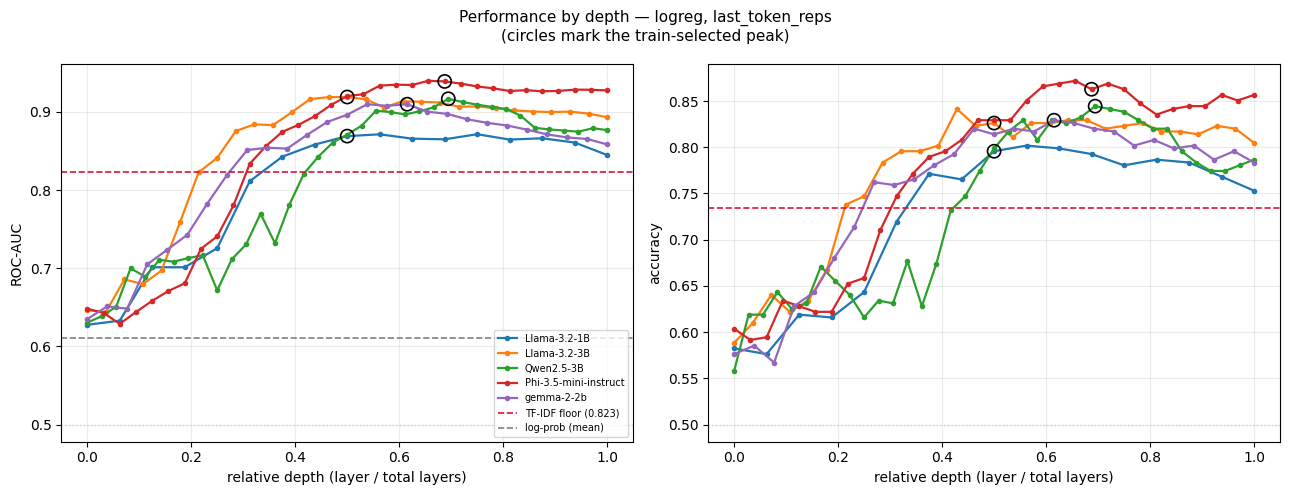

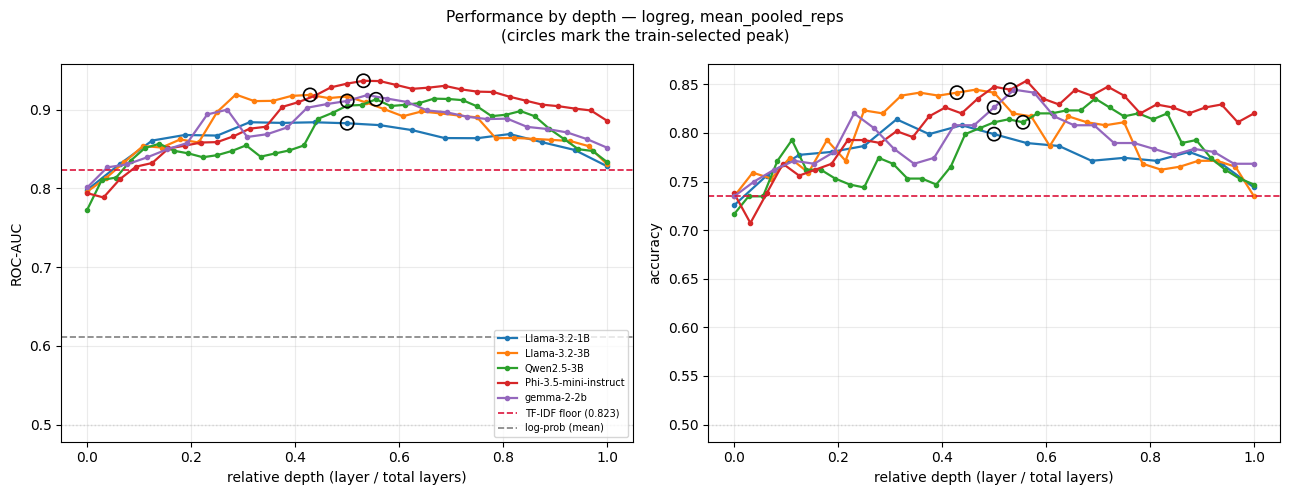

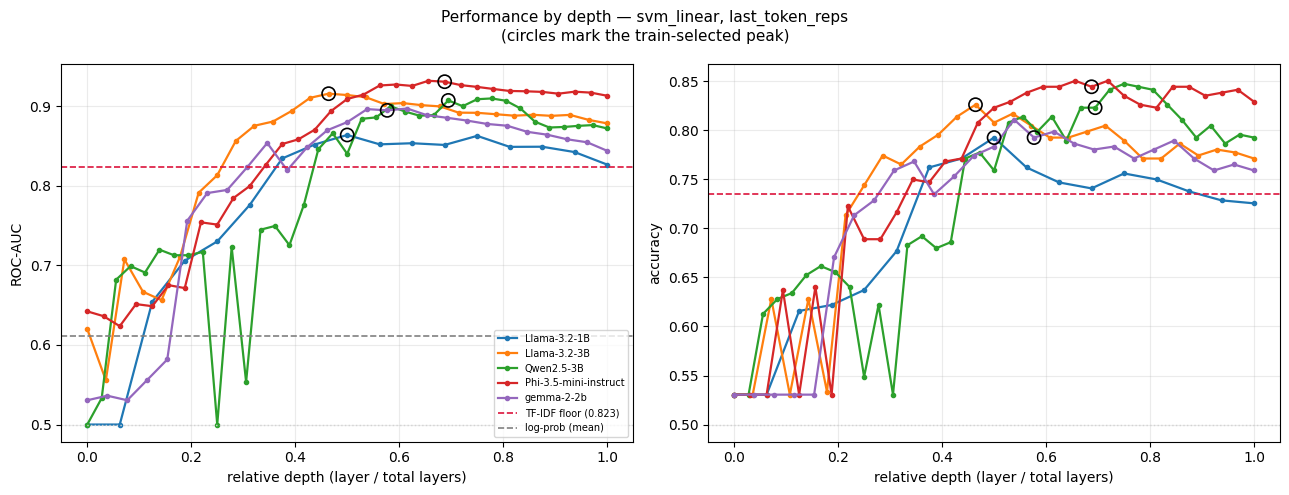

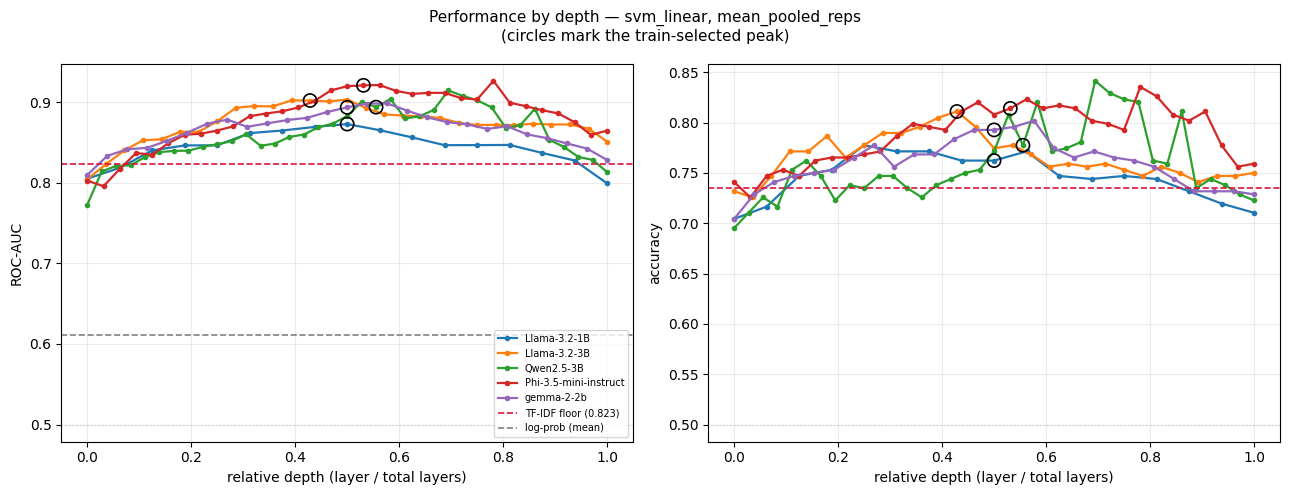

In [43]:
COLORS = plt.cm.tab10(np.linspace(0, 1, 10))


def sweep_of(model, probe, strategy):
    g = sweeps[(model, probe)]
    return g[g.strategy == strategy].sort_values("layer")


# --- Figure 1: depth curves with floors, AUC and accuracy -------------------
for probe in PROBES:
    for strategy in STRATEGIES:
        fig, axes = plt.subplots(1, 2, figsize=(13, 5))
        for j, (metric, col) in enumerate([("ROC-AUC", "test_auc"),
                                           ("accuracy", "test_acc")]):
            ax = axes[j]
            for i, m in enumerate(MODEL_NAMES):
                if (m, probe) not in AVAILABLE:
                    continue
                g = sweep_of(m, probe, strategy)
                ax.plot(g["layer"] / g["layer"].max(), g[col], marker="o", ms=3,
                        lw=1.6, color=COLORS[i], label=m)
                L = peak_layer(m, probe, strategy, "cv_best_score")
                r = g[g.layer == L].iloc[0]
                ax.scatter([L / g["layer"].max()], [r[col]], s=90,
                           facecolors="none", edgecolors="black", lw=1.2, zorder=5)
            floor = ladder_full.loc[ladder_full.rung.str.startswith("4."),
                                    "auc" if j == 0 else "accuracy"].iloc[0]
            ax.axhline(floor, ls="--", c="crimson", lw=1.2,
                       label=f"TF-IDF floor ({floor:.3f})")
            if j == 0:
                ax.axhline(float(logprob_baselines[logprob_baselines.model.isin(CORE_MODEL_NAMES)]["test_oriented_auc"].mean()),
                           ls="--", c="grey", lw=1.2, label="log-prob (mean)")
            ax.axhline(0.5, ls=":", c="lightgrey", lw=1)
            ax.set_xlabel("relative depth (layer / total layers)")
            ax.set_ylabel(metric)
            ax.grid(alpha=0.25)
        axes[0].legend(fontsize=7, loc="lower right")
        fig.suptitle(f"Performance by depth — {probe}, {strategy}\n"
                     f"(circles mark the train-selected peak)", fontsize=11)
        fig.tight_layout()
        save_fig(fig, f"fig01_depth_{probe}_{strategy}",
                 f"Probe performance by normalised depth with baseline floors, "
                 f"{probe}, {strategy}.")
        plt.show()

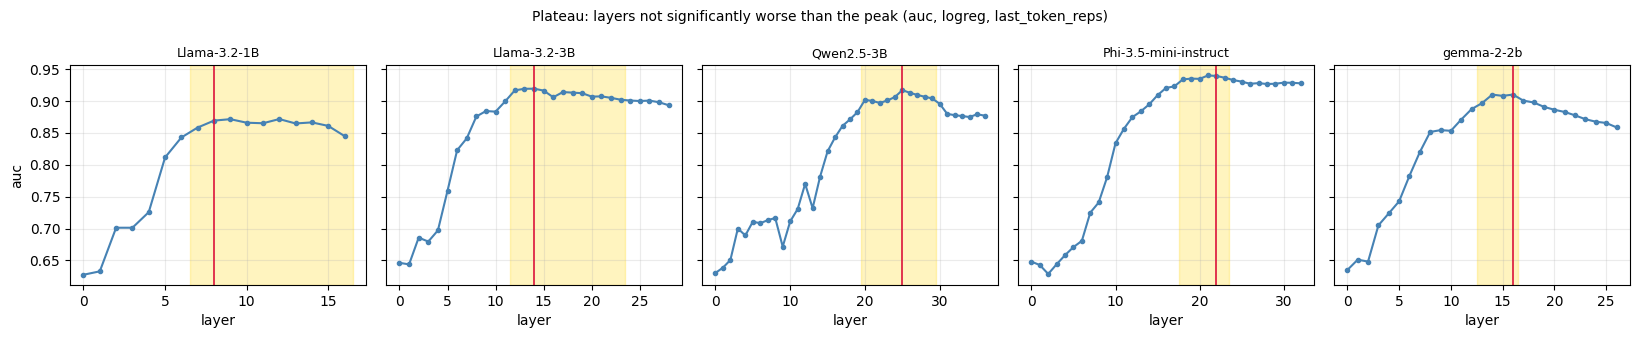

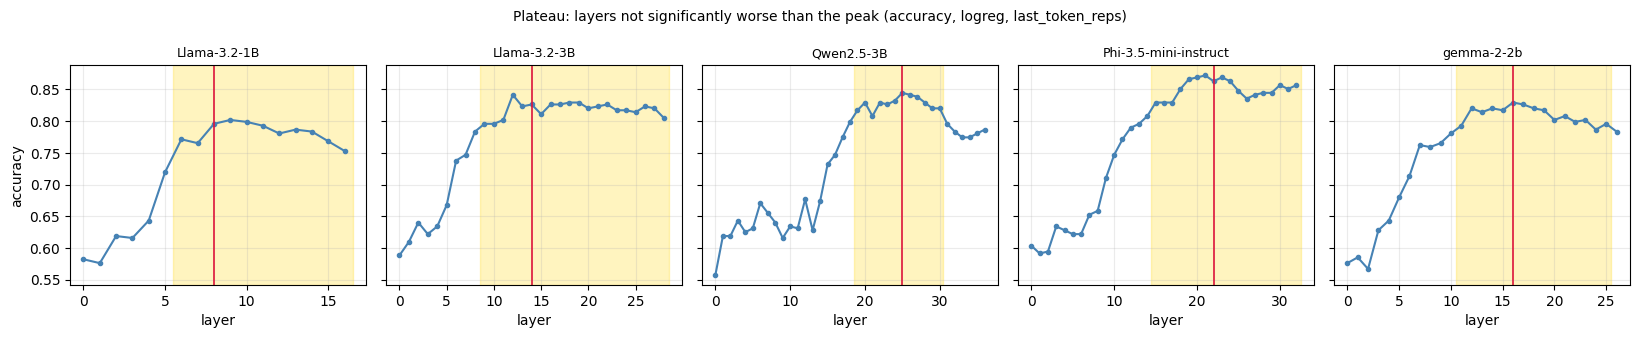

In [44]:
# --- Figure 2: per-model panels with plateau band --------------------------
for metric, col in [("auc", "test_auc"), ("accuracy", "test_acc")]:
    fig, axes = plt.subplots(1, len(MODEL_NAMES),
                             figsize=(3.3 * len(MODEL_NAMES), 3.4), sharey=True)
    for ax, m in zip(np.atleast_1d(axes), MODEL_NAMES):
        if (m, PRIMARY_PROBE) not in AVAILABLE:
            continue
        g = sweep_of(m, PRIMARY_PROBE, PRIMARY_STRATEGY)
        ax.plot(g["layer"], g[col], marker="o", ms=3, lw=1.5, color="steelblue")
        b = plateau[(plateau.model == m) & (plateau.probe == PRIMARY_PROBE)
                    & (plateau.strategy == PRIMARY_STRATEGY)
                    & (plateau.metric == metric)]
        if len(b):
            ax.axvspan(b.iloc[0]["plateau_lo"] - 0.5, b.iloc[0]["plateau_hi"] + 0.5,
                       color="gold", alpha=0.25, zorder=0)
            ax.axvline(b.iloc[0]["peak_layer"], c="crimson", lw=1.2)
        ax.set_title(m, fontsize=9)
        ax.set_xlabel("layer")
        ax.grid(alpha=0.25)
    np.atleast_1d(axes)[0].set_ylabel(metric)
    fig.suptitle(f"Plateau: layers not significantly worse than the peak "
                 f"({metric}, {PRIMARY_PROBE}, {PRIMARY_STRATEGY})", fontsize=10)
    fig.tight_layout()
    save_fig(fig, f"fig02_plateau_{metric}",
             f"Per-model {metric} by layer; the shaded band marks layers the "
             f"peak does not significantly beat.")
    plt.show()

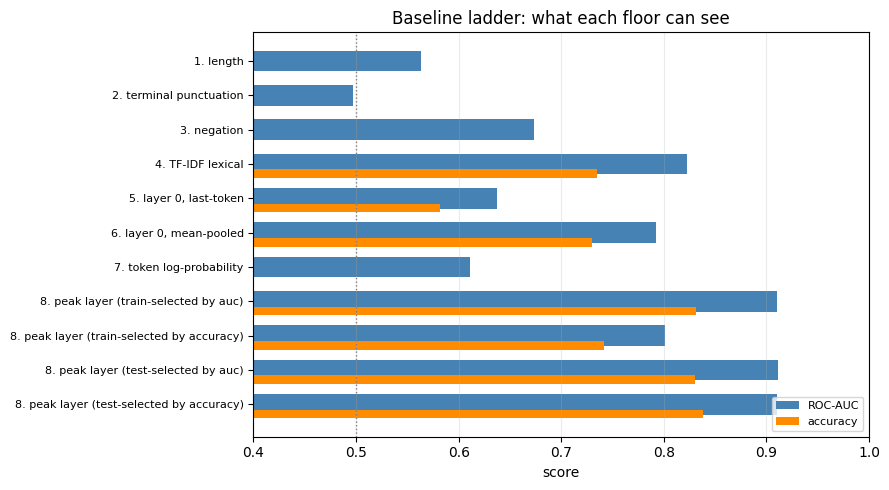

In [45]:
# --- Figure 3: baseline ladder ---------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5))
d = ladder_full.iloc[::-1]
ypos = np.arange(len(d))
ax.barh(ypos, d["auc"], color="steelblue", height=0.6, label="ROC-AUC")
mask = d["accuracy"].notna()
ax.barh(ypos[mask.to_numpy()] - 0.28, d.loc[mask, "accuracy"],
        color="darkorange", height=0.25, label="accuracy")
ax.set_yticks(ypos)
ax.set_yticklabels(d["rung"], fontsize=8)
ax.axvline(0.5, ls=":", c="grey", lw=1)
ax.set_xlim(0.4, 1.0)
ax.set_xlabel("score")
ax.legend(fontsize=8, loc="lower right")
ax.grid(axis="x", alpha=0.25)
ax.set_title("Baseline ladder: what each floor can see")
fig.tight_layout()
save_fig(fig, "fig03_baseline_ladder",
         "Ordered baselines from surface features to the full transformer.")
plt.show()

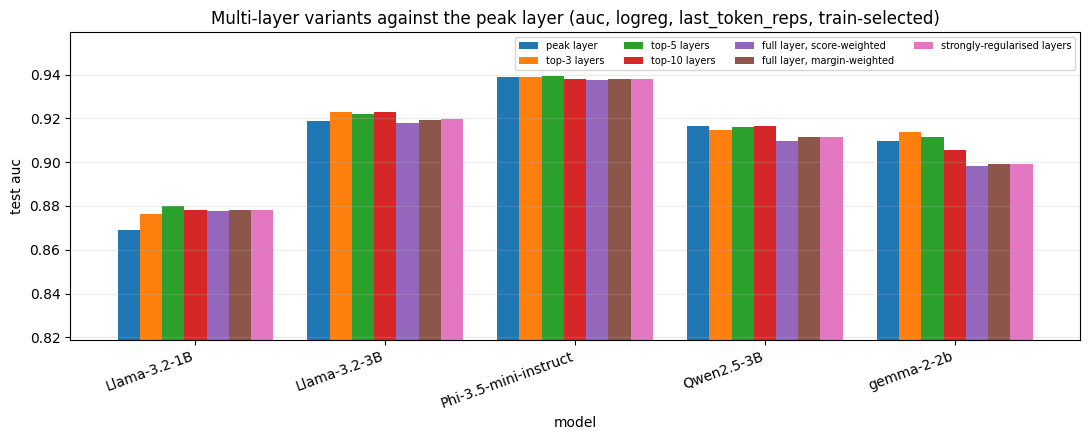

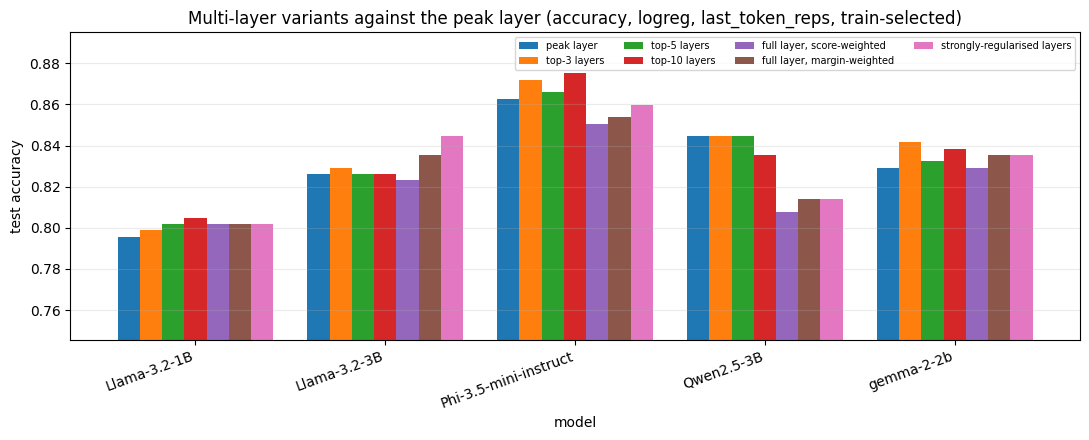

In [46]:
# --- Figure 4: variants against the peak layer -----------------------------
for metric in ["auc", "accuracy"]:
    v = variants[(variants.probe == PRIMARY_PROBE)
                 & (variants.strategy == PRIMARY_STRATEGY)
                 & (variants.selected_on == "train") & (variants.ranked_by == "auc")]
    piv = v.pivot(index="model", columns="variant", values=metric)
    piv = piv[[c for c in VARIANT_ORDER if c in piv.columns]]
    fig, ax = plt.subplots(figsize=(11, 4.5))
    piv.plot(kind="bar", ax=ax, width=0.82)
    ax.set_ylabel(f"test {metric}")
    ax.set_ylim(max(0.5, float(piv.min().min()) - 0.05), float(piv.max().max()) + 0.02)
    ax.legend(fontsize=7, ncol=4)
    ax.grid(axis="y", alpha=0.25)
    ax.set_title(f"Multi-layer variants against the peak layer "
                 f"({metric}, {PRIMARY_PROBE}, {PRIMARY_STRATEGY}, train-selected)")
    plt.xticks(rotation=20, ha="right")
    fig.tight_layout()
    save_fig(fig, f"fig04_variants_{metric}",
             f"Every variant's {metric} beside the single peak layer.")
    plt.show()

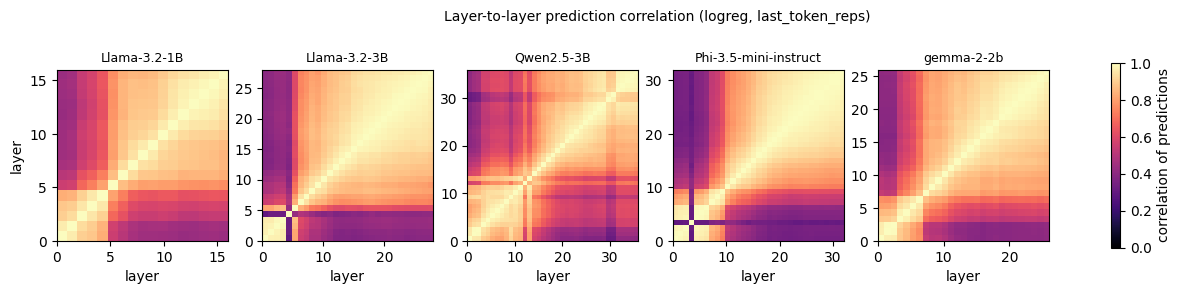

In [47]:
# --- Figure 5: redundancy heatmaps -----------------------------------------
fig, axes = plt.subplots(1, len(MODEL_NAMES),
                         figsize=(3.2 * len(MODEL_NAMES), 3.0))
for ax, m in zip(np.atleast_1d(axes), MODEL_NAMES):
    key = (m, PRIMARY_PROBE, PRIMARY_STRATEGY)
    if key not in corr_mats:
        continue
    layers, C = corr_mats[key]
    im = ax.imshow(C, vmin=0, vmax=1, cmap="magma", origin="lower",
                   extent=[layers.min(), layers.max(), layers.min(), layers.max()])
    ax.set_title(m, fontsize=9)
    ax.set_xlabel("layer")
np.atleast_1d(axes)[0].set_ylabel("layer")
fig.colorbar(im, ax=np.atleast_1d(axes).tolist(), shrink=0.8,
             label="correlation of predictions")
fig.suptitle(f"Layer-to-layer prediction correlation "
             f"({PRIMARY_PROBE}, {PRIMARY_STRATEGY})", fontsize=10)
save_fig(fig, "fig05_redundancy_heatmap",
         "Correlation between per-layer predicted probabilities.")
plt.show()

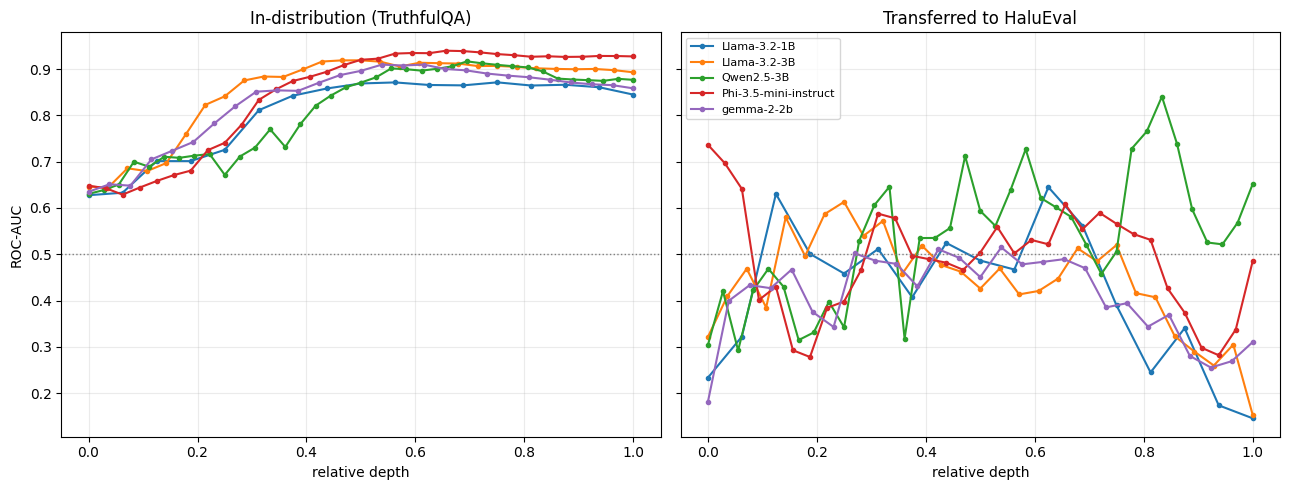

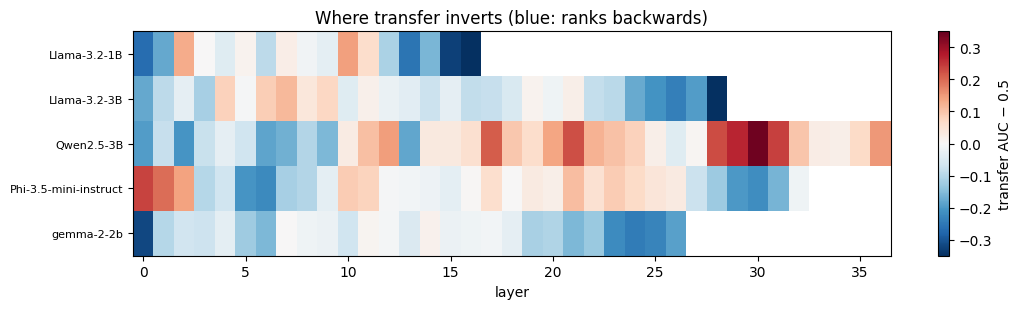

In [48]:
# --- Figure 6: transfer, in-distribution beside out-of-distribution --------
rows_m = []
if len(ood_curves):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
    for i, m in enumerate(MODEL_NAMES):
        if (m, PRIMARY_PROBE) not in AVAILABLE:
            continue
        g = sweep_of(m, PRIMARY_PROBE, PRIMARY_STRATEGY)
        axes[0].plot(g["layer"] / g["layer"].max(), g["test_auc"],
                     marker="o", ms=3, lw=1.5, color=COLORS[i], label=m)
        s = ood_curves[(ood_curves.model == m) & (ood_curves.probe == PRIMARY_PROBE)
                       & (ood_curves.strategy == PRIMARY_STRATEGY)].sort_values("layer")
        if len(s):
            axes[1].plot(s["depth_frac"], s["ood_auc"], marker="o", ms=3,
                         lw=1.5, color=COLORS[i], label=m)
    axes[0].set_title("In-distribution (TruthfulQA)")
    axes[1].set_title("Transferred to HaluEval")
    for ax in axes:
        ax.axhline(0.5, ls=":", c="grey", lw=1)
        ax.set_xlabel("relative depth")
        ax.grid(alpha=0.25)
    axes[0].set_ylabel("ROC-AUC")
    axes[1].legend(fontsize=8)
    fig.tight_layout()
    save_fig(fig, "fig06_ood_vs_id",
             "The same probes in distribution and transferred.")
    plt.show()

    # inversion map
    rows_m = [m for m in MODEL_NAMES if (m, PRIMARY_PROBE) in AVAILABLE
              and len(ood_curves[(ood_curves.model == m)
                                 & (ood_curves.probe == PRIMARY_PROBE)
                                 & (ood_curves.strategy == PRIMARY_STRATEGY)])]
if RUN_OOD and len(ood_curves) and rows_m:
    fig, ax = plt.subplots(figsize=(11, 3.2))
    width = max(len(ood_curves[(ood_curves.model == m)
                               & (ood_curves.probe == PRIMARY_PROBE)
                               & (ood_curves.strategy == PRIMARY_STRATEGY)])
                for m in rows_m)
    grid = np.full((len(rows_m), width), np.nan)
    for i, m in enumerate(rows_m):
        s = ood_curves[(ood_curves.model == m) & (ood_curves.probe == PRIMARY_PROBE)
                       & (ood_curves.strategy == PRIMARY_STRATEGY)].sort_values("layer")
        grid[i, :len(s)] = s["ood_auc"].to_numpy() - 0.5
    im = ax.imshow(grid, cmap="RdBu_r", vmin=-0.35, vmax=0.35, aspect="auto")
    ax.set_yticks(range(len(rows_m)))
    ax.set_yticklabels(rows_m, fontsize=8)
    ax.set_xlabel("layer")
    fig.colorbar(im, ax=ax, label="transfer AUC − 0.5")
    ax.set_title("Where transfer inverts (blue: ranks backwards)")
    fig.tight_layout()
    save_fig(fig, "fig07_ood_inversion_map",
             "Transfer AUC relative to chance, per layer and model.")
    plt.show()

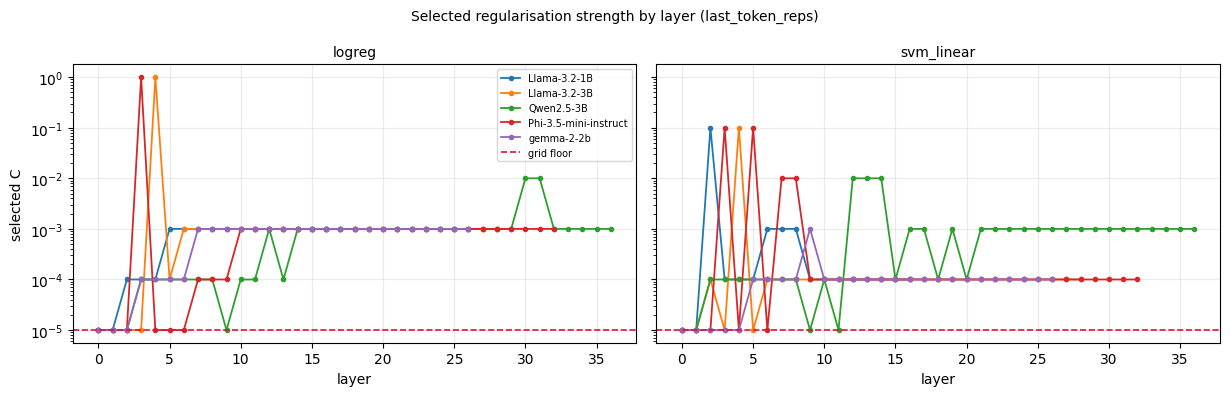

In [49]:
# --- Figure 8: selected regularisation by layer ----------------------------
fig, axes = plt.subplots(1, len(PROBES), figsize=(6.2 * len(PROBES), 4), sharey=True)
for ax, probe in zip(np.atleast_1d(axes), PROBES):
    for i, m in enumerate(MODEL_NAMES):
        if (m, probe) not in AVAILABLE:
            continue
        g = sweep_of(m, probe, PRIMARY_STRATEGY)
        ax.semilogy(g["layer"], g["C"], marker="o", ms=3, lw=1.3,
                    color=COLORS[i], label=m)
    ax.axhline(1e-5, ls="--", c="crimson", lw=1.2, label="grid floor")
    ax.set_title(probe, fontsize=10)
    ax.set_xlabel("layer")
    ax.grid(alpha=0.25)
np.atleast_1d(axes)[0].set_ylabel("selected C")
np.atleast_1d(axes)[0].legend(fontsize=7)
fig.suptitle(f"Selected regularisation strength by layer ({PRIMARY_STRATEGY})",
             fontsize=10)
fig.tight_layout()
save_fig(fig, "fig08_selected_C",
         "Chosen C per layer; points on the red line sat at the grid floor.")
plt.show()

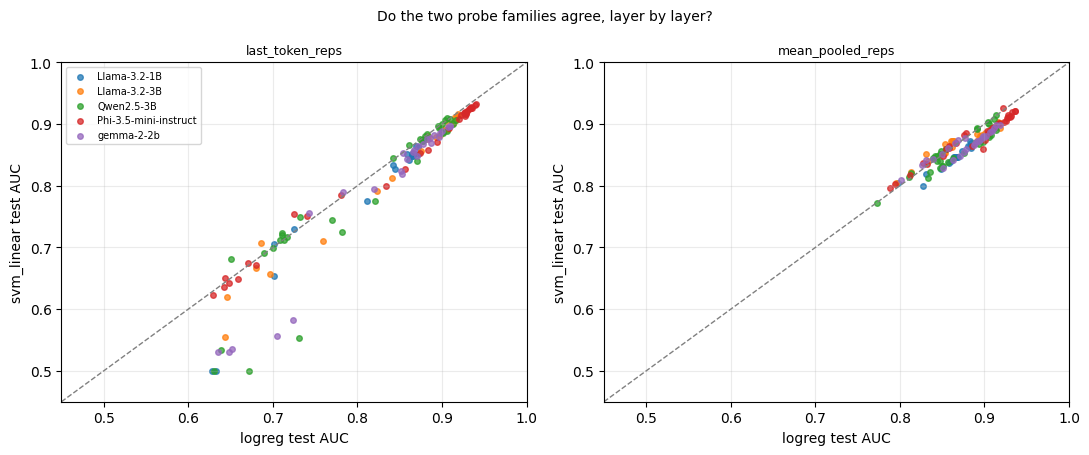

In [50]:
# --- Figure 9: probe families against each other ---------------------------
if all((m, p) in AVAILABLE for m in MODEL_NAMES for p in PROBES):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
    for j, strategy in enumerate(STRATEGIES):
        ax = axes[j]
        for i, m in enumerate(MODEL_NAMES):
            a = sweep_of(m, "logreg", strategy)["test_auc"].to_numpy()
            b = sweep_of(m, "svm_linear", strategy)["test_auc"].to_numpy()
            n = min(len(a), len(b))
            ax.scatter(a[:n], b[:n], s=16, alpha=0.75, color=COLORS[i], label=m)
        lim = [0.45, 1.0]
        ax.plot(lim, lim, ls="--", c="grey", lw=1)
        ax.set_xlim(lim); ax.set_ylim(lim)
        ax.set_xlabel("logreg test AUC")
        ax.set_ylabel("svm_linear test AUC")
        ax.set_title(strategy, fontsize=9)
        ax.grid(alpha=0.25)
    axes[0].legend(fontsize=7, loc="upper left")
    fig.suptitle("Do the two probe families agree, layer by layer?", fontsize=10)
    fig.tight_layout()
    save_fig(fig, "fig09_probe_agreement",
             "Per-layer AUC of one probe family against the other.")
    plt.show()

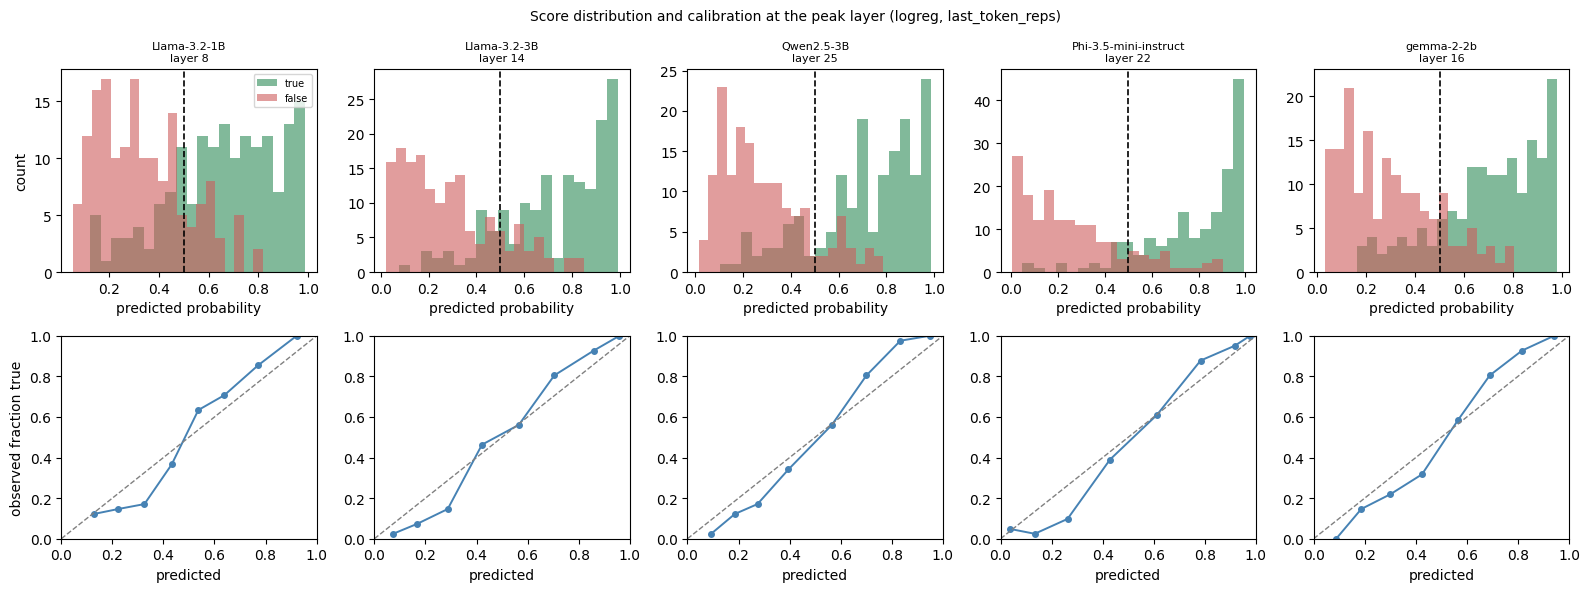

In [51]:
# --- Figure 10: score distributions and calibration at the peak ------------
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(2, len(MODEL_NAMES),
                         figsize=(3.2 * len(MODEL_NAMES), 6))
for j, m in enumerate(MODEL_NAMES):
    if (m, PRIMARY_PROBE) not in AVAILABLE:
        continue
    y = meta[m]["test"]["label"]
    L = peak_layer(m, PRIMARY_PROBE, PRIMARY_STRATEGY, "cv_best_score")
    s = probs_store[(m, PRIMARY_PROBE)][f"{PRIMARY_STRATEGY}__L{L}__{PRIMARY_PROBE}"]

    ax = axes[0, j]
    ax.hist(s[y == 1], bins=20, alpha=0.6, label="true", color="seagreen")
    ax.hist(s[y == 0], bins=20, alpha=0.6, label="false", color="indianred")
    ax.axvline(THRESHOLD, c="black", lw=1.2, ls="--")
    ax.set_title(f"{m}\nlayer {L}", fontsize=8)
    ax.set_xlabel("predicted probability")

    ax = axes[1, j]
    frac, mean_pred = calibration_curve(y, s, n_bins=8, strategy="quantile")
    ax.plot(mean_pred, frac, marker="o", ms=4, lw=1.4, color="steelblue")
    ax.plot([0, 1], [0, 1], ls="--", c="grey", lw=1)
    ax.set_xlabel("predicted")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
axes[0, 0].legend(fontsize=7)
axes[0, 0].set_ylabel("count")
axes[1, 0].set_ylabel("observed fraction true")
fig.suptitle(f"Score distribution and calibration at the peak layer "
             f"({PRIMARY_PROBE}, {PRIMARY_STRATEGY})", fontsize=10)
fig.tight_layout()
save_fig(fig, "fig10_scores_and_calibration",
         "Predicted-probability histograms by class, and reliability curves, "
         "at each model's peak layer.")
plt.show()

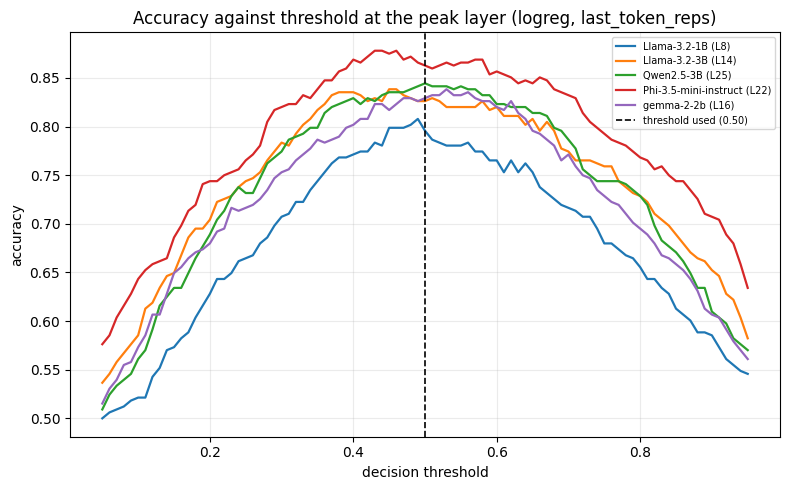

                model  layer  acc_at_0.50  best_threshold  acc_at_best  gain_from_tuning
         Llama-3.2-1B      8       0.7957            0.49       0.8079            0.0122
         Llama-3.2-3B     14       0.8262            0.45       0.8384            0.0122
           Qwen2.5-3B     25       0.8445            0.50       0.8445            0.0000
Phi-3.5-mini-instruct     22       0.8628            0.43       0.8780            0.0152
           gemma-2-2b     16       0.8293            0.53       0.8384            0.0091

best_threshold is the test-optimal cut and is an upper bound, not a
rule: choosing it on the test set is selection on the evaluation data.
All accuracy elsewhere in this notebook uses the fixed 0.50.


In [52]:
# --- Figure 11: accuracy against threshold ---------------------------------
fig, ax = plt.subplots(figsize=(8, 5))
grid = np.linspace(0.05, 0.95, 91)
tsweep = []
for i, m in enumerate(MODEL_NAMES):
    if (m, PRIMARY_PROBE) not in AVAILABLE:
        continue
    y = meta[m]["test"]["label"]
    L = peak_layer(m, PRIMARY_PROBE, PRIMARY_STRATEGY, "cv_best_score")
    s = probs_store[(m, PRIMARY_PROBE)][f"{PRIMARY_STRATEGY}__L{L}__{PRIMARY_PROBE}"]
    accs = [accuracy_score(y, (s >= t).astype(int)) for t in grid]
    ax.plot(grid, accs, lw=1.6, color=COLORS[i], label=f"{m} (L{L})")
    best_i = int(np.argmax(accs))
    tsweep.append({"model": m, "layer": L,
                   "acc_at_0.50": round(float(
                       accuracy_score(y, (s >= THRESHOLD).astype(int))), 4),
                   "best_threshold": round(float(grid[best_i]), 3),
                   "acc_at_best": round(float(accs[best_i]), 4),
                   "gain_from_tuning": round(float(accs[best_i]) - float(
                       accuracy_score(y, (s >= THRESHOLD).astype(int))), 4)})
ax.axvline(THRESHOLD, c="black", ls="--", lw=1.2, label="threshold used (0.50)")
ax.set_xlabel("decision threshold")
ax.set_ylabel("accuracy")
ax.grid(alpha=0.25)
ax.legend(fontsize=7)
ax.set_title(f"Accuracy against threshold at the peak layer "
             f"({PRIMARY_PROBE}, {PRIMARY_STRATEGY})")
fig.tight_layout()
save_fig(fig, "fig11_accuracy_vs_threshold",
         "How accuracy varies with the decision threshold.")
plt.show()

tsweep = pd.DataFrame(tsweep)
save_table(tsweep, "20_threshold_sweep")
print("\nbest_threshold is the test-optimal cut and is an upper bound, not a")
print("rule: choosing it on the test set is selection on the evaluation data.")
print("All accuracy elsewhere in this notebook uses the fixed 0.50.")

## Step 6.15: Results Manifest Compilation


In [53]:
figman = pd.DataFrame(FIGURES)
figman.to_csv(os.path.join(OUT_DIR, "figure_manifest.csv"), index=False)

tables = sorted(f for f in os.listdir(OUT_DIR) if f.endswith(".csv"))
print("tables")
for t in tables:
    print(f"  {t}")
print(f"\nfigures ({len(FIGURES)})")
for f in FIGURES:
    print(f"  {f['file']:42s} {f['caption']}")

summary_json = {
    "threshold": THRESHOLD,
    "n_boot": N_BOOT,
    "random_state": RANDOM_STATE,
    "models": MODEL_NAMES,
    "probes": PROBES,
    "strategies": STRATEGIES,
    "top_k": TOP_K,
    "selection_bases": [{"selected_on": a, "ranked_by": b, "column": c}
                        for a, b, c in SELECTION_BASES],
    "n_test_rows": int(n_rows),
    "n_test_questions": int(n_q),
}
with open(os.path.join(OUT_DIR, "run_config.json"), "w") as fh:
    json.dump(summary_json, fh, indent=2)
print(f"\nconfiguration written to {os.path.join(OUT_DIR, 'run_config.json')}")

tables
  00_artefact_manifest.csv
  01_sweep_all.csv
  02_bootstrap_width_comparison.csv
  03_logprob_baseline.csv
  04_baseline_ladder.csv
  05_per_layer_full.csv
  06_peak_selection.csv
  07_selection_penalty.csv
  08_plateau_detail.csv
  09_plateau_summary.csv
  10_layer_redundancy.csv
  11_variants_all.csv
  12_variant_summary.csv
  13_ood_curves_by_layer.csv
  14_ood_transfer.csv
  15_ood_variants.csv
  16_ood_mechanism_check.csv
  17_probe_family_comparison.csv
  18_pooling_comparison.csv
  19_diagnostics.csv
  20_threshold_sweep.csv
  figure_manifest.csv

figures (16)
  fig01_depth_logreg_last_token_reps.png     Probe performance by normalised depth with baseline floors, logreg, last_token_reps.
  fig01_depth_logreg_mean_pooled_reps.png    Probe performance by normalised depth with baseline floors, logreg, mean_pooled_reps.
  fig01_depth_svm_linear_last_token_reps.png Probe performance by normalised depth with baseline floors, svm_linear, last_token_reps.
  fig01_depth_svm_linea

# Part 7: Paired Probe vs. TF-IDF Statistical Comparison

Conduct paired statistical tests between the train-selected peak probe and the TF-IDF lexical baseline on TruthfulQA test answers:
1. **Paired Difference Intervals:** Paired cluster bootstrap for difference in AUC and Accuracy.
2. **Prediction Agreement Analysis:** Contingency table (both correct, probe-only, TF-IDF-only, both incorrect), exact binomial test on disagreements, and Spearman rank correlation.


In [ ]:
from scipy.stats import rankdata, spearmanr, binomtest
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline


def pv_auc(y, s):
    r = rankdata(s)
    n1 = float(y.sum()); n0 = float(y.size - n1)
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2.0) / (n1 * n0)


def pv_acc(y, s):
    return float(np.mean((s >= THRESHOLD).astype(np.int64) == y))


def pv_draw(n, groups=None):
    if groups is None:
        return lambda rng: rng.randint(0, n, n)
    keys = np.unique(groups)
    members = [np.where(groups == g)[0] for g in keys]
    k = len(keys)
    return lambda rng: np.concatenate([members[i] for i in rng.randint(0, k, k)])


def pv_interval(y, a, b, metric_fn, groups=None):
    # 95% percentile interval on metric(a) - metric(b), one shared resample
    draw = pv_draw(len(y), groups)
    rng = np.random.RandomState(RANDOM_STATE)
    d = []
    for _ in range(N_BOOT):
        idx = draw(rng)
        if len(np.unique(y[idx])) < 2:
            continue
        d.append(metric_fn(y[idx], a[idx]) - metric_fn(y[idx], b[idx]))
    d = np.array(d)
    return float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))


def pv_texts(df):
    t, y = [], []
    for _, r in df.iterrows():
        t.append(r["right_answer"]);        y.append(1)
        t.append(r["hallucinated_answer"]); y.append(0)
    return t, np.array(y)


def pv_test_meta(model):
    files = sorted(glob.glob(os.path.join(MODEL_BY_NAME[model]["extract_tqa_path"], "test_chunk*.npz")))
    if not files:
        raise FileNotFoundError(f"no test chunks for {model}")
    y, q = [], []
    for f in files:
        z = np.load(f)
        y.append(z["label"]); q.append(z["question_idx"])
    return np.concatenate(y), np.concatenate(q)


_tqa = pd.read_parquet(SHARED["tqa_parquet"])
_sp = np.load(SHARED["tqa_split"])
pv_txt_tr, pv_y_tr = pv_texts(_tqa.iloc[_sp["train_idx"]].reset_index(drop=True))
pv_txt_te, pv_y_te = pv_texts(_tqa.iloc[_sp["test_idx"]].reset_index(drop=True))

pv_lex = make_pipeline(
    TfidfVectorizer(ngram_range=LEXICAL["ngram_range"], min_df=LEXICAL["min_df"],
                    sublinear_tf=LEXICAL["sublinear_tf"]),
    LogisticRegression(max_iter=LEXICAL["max_iter"], random_state=RANDOM_STATE),
).fit(pv_txt_tr, pv_y_tr)
pv_lex_scores = pv_lex.predict_proba(pv_txt_te)[:, 1]
print(f"TF-IDF on TruthfulQA test: auc={pv_auc(pv_y_te, pv_lex_scores):.4f}  "
      f"acc={pv_acc(pv_y_te, pv_lex_scores):.4f}  n_rows={len(pv_y_te)}")

In [54]:
paired_rows, agree_rows = [], []

for entry in MODEL_REGISTRY:
    model = entry["name"]
    pf = probe_files(model, PRIMARY_PROBE)
    sweep_p, probs_p = pf["sweep"], pf["probs"]
    if not (os.path.isfile(sweep_p) and os.path.isfile(probs_p)):
        print(f"[skip] {model}: sweep or probability file not found")
        continue

    y, q = pv_test_meta(model)
    # weak structural checks (labels alternate by construction); true row-for-row
    # alignment of text and hidden states is the alignment gate's job
    assert len(y) == len(pv_y_te), f"[{model}] row count differs from the text sequence"
    assert np.array_equal(y, pv_y_te), f"[{model}] label order differs from the text sequence"
    assert (y[0::2] == 1).all() and (y[1::2] == 0).all(), f"[{model}] rows are not (right, wrong) pairs"

    sw = pd.read_csv(sweep_p)
    sw = sw[sw.strategy == PRIMARY_STRATEGY]
    layer = int(sw.loc[sw["cv_best_score"].idxmax(), "layer"])      # train-side selection
    n_states = int(sw["layer"].max()) + 1
    s = np.load(probs_p)[f"{PRIMARY_STRATEGY}__L{layer}__{PRIMARY_PROBE}"]

    row = {"model": model, "peak_layer": f"{layer}/{n_states}"}
    for name, fn in (("auc", pv_auc), ("acc", pv_acc)):
        obs_p, obs_t = fn(y, s), fn(y, pv_lex_scores)
        lo_r, hi_r = pv_interval(y, s, pv_lex_scores, fn, groups=None)
        lo_c, hi_c = pv_interval(y, s, pv_lex_scores, fn, groups=q)
        row.update({
            f"probe_{name}": round(obs_p, 4), f"tfidf_{name}": round(obs_t, 4),
            f"{name}_diff": round(obs_p - obs_t, 4),
            f"{name}_ci_row": f"[{lo_r:+.4f}, {hi_r:+.4f}]",
            f"{name}_ci_cluster": f"[{lo_c:+.4f}, {hi_c:+.4f}]",
        })
    paired_rows.append(row)

    p_ok = s[0::2] > s[1::2]
    t_ok = pv_lex_scores[0::2] > pv_lex_scores[1::2]
    both = int((p_ok & t_ok).sum())
    p_only = int((p_ok & ~t_ok).sum())
    t_only = int((~p_ok & t_ok).sum())
    neither = int((~p_ok & ~t_ok).sum())
    disc = p_only + t_only
    p_val = binomtest(p_only, disc, 0.5).pvalue if disc > 0 else float("nan")
    agree_rows.append({
        "model": model, "n_questions": len(p_ok),
        "both_right": both, "probe_only": p_only, "tfidf_only": t_only, "both_wrong": neither,
        "exact_p_disagreements": round(p_val, 4),
        "spearman_row_scores": round(float(spearmanr(s, pv_lex_scores)[0]), 4),
        "spearman_pair_margin": round(float(spearmanr(
            s[0::2] - s[1::2], pv_lex_scores[0::2] - pv_lex_scores[1::2])[0]), 4),
    })

paired = pd.DataFrame(paired_rows)
agree = pd.DataFrame(agree_rows)
paired.to_csv(os.path.join(OUT_DIR, "22_probe_vs_tfidf_paired.csv"), index=False)
agree.to_csv(os.path.join(OUT_DIR, "23_probe_tfidf_agreement.csv"), index=False)

print(f"Output 1 -- {PRIMARY_PROBE} / {PRIMARY_STRATEGY}, peak layer chosen from cv_best_score (train only)\n")
print(paired[["model", "peak_layer", "probe_auc", "tfidf_auc", "auc_diff", "auc_ci_row", "auc_ci_cluster"]].to_string(index=False))
print()
print(paired[["model", "probe_acc", "tfidf_acc", "acc_diff", "acc_ci_row", "acc_ci_cluster"]].to_string(index=False))
print("\nOutput 2 -- do the two methods get the same questions right?\n")
print(agree.to_string(index=False))
print("\nexact_p tests whether the questions where only one method is right split evenly.")
print("Spearman near 1: the two scorings rank examples almost identically.")

Output 1 -- logreg / last_token_reps, peak layer chosen from cv_best_score (train only)

                model peak_layer  probe_auc  tfidf_auc  auc_diff        auc_ci_row    auc_ci_cluster
         Llama-3.2-1B       8/17     0.8689     0.8230    0.0459  [+0.0135, +0.0782]  [+0.0096, +0.0820]
         Llama-3.2-3B      14/29     0.9189     0.8230    0.0959  [+0.0610, +0.1309]  [+0.0585, +0.1362]
           Qwen2.5-3B      25/37     0.9167     0.8230    0.0937  [+0.0592, +0.1281]  [+0.0573, +0.1322]
Phi-3.5-mini-instruct      22/33     0.9389     0.8230    0.1159  [+0.0780, +0.1539]  [+0.0748, +0.1593]
           gemma-2-2b      16/27     0.9098     0.8230    0.0867  [+0.0531, +0.1204]  [+0.0514, +0.1263]

                model  probe_acc  tfidf_acc  acc_diff        acc_ci_row    acc_ci_cluster
         Llama-3.2-1B     0.8171     0.7561    0.0610  [+0.0183, +0.1037]  [+0.0152, +0.1037]
         Llama-3.2-3B     0.8476     0.7561    0.0915  [+0.0488, +0.1341]  [+0.0457, +0.1402]
      

# Part 8: Execution Manifest

Generate runtime manifest recording system configuration, environment library versions, and SHA-256 hashes for all output files.


In [55]:
import json, sys, datetime, importlib

versions = {"python": platform.python_version()}
for mod in ("numpy", "pandas", "scipy", "sklearn", "matplotlib", "torch", "transformers"):
    try:
        versions[mod] = importlib.import_module(mod).__version__
    except Exception:
        versions[mod] = None

outputs = []
for root, _, files in os.walk(OUT_DIR):
    for f in sorted(files):
        p = os.path.join(root, f)
        outputs.append({"file": os.path.relpath(p, OUT_DIR).replace(os.sep, "/"),
                        "bytes": os.path.getsize(p)})

manifest_run = {
    "written_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
    "config": {
        "run": RUN, "data": DATA, "prompt": PROMPT, "probe_spec": PROBE_SPEC,
        "lexical": LEXICAL, "stats": STATS, "shared": SHARED, "probe_files": PROBE_FILES,
        "active_models": MODEL_REGISTRY,
    },
    "versions": versions,
    "n_outputs": len(outputs),
    "outputs": outputs,
}
with open(SHARED["run_manifest"], "w", encoding="utf-8") as fh:
    json.dump(manifest_run, fh, indent=2)
print(f"written: {SHARED['run_manifest']}  ({len(outputs)} output files)")

Wrote results/run_manifest.json with 25 output files.
Run manifest complete.
